## Pattern 1 — Sliding Window (Fixed Size)

**Importance:** ★★★★★

### Story
You’re watching a train pass a window. Each carriage rolls into view as the last one disappears. You never need to go back and recount — you just add what’s entering and subtract what’s leaving. That running adjustment is the whole trick. The window is always exactly `k` elements wide, and at every position you already know your total — you’re just swapping one element for another. No loops within loops, no starting over. One pass through the array, one running sum, and the answer assembles itself.

### When to Use
*   Fixed-size subarray questions
*   Maximum/average over every window of size `k`
*   Streaming or online data over a fixed window

### Core Idea
Keep a running total of exactly `k` elements. On each step, add the new element coming in from the right and subtract the one falling off the left.

### Pitfalls
*   Forgetting to subtract the element that just left the window
*   Getting the window boundaries wrong --- especially off-by-one on the starting index

### Mini Example
**Example:** `arr = [2,1,5,2,3,2]`, `k = 2`. The windows give sums `3, 6, 7, 5, 5`. Best is `7`.

## ![][image1]

[image1]: <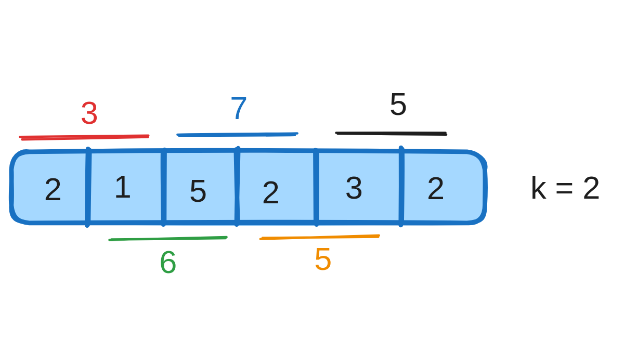>

In [ ]:
def fixed_size(arr, max_size):
    if len(arr) < max_size:
        return 0

    current_state = 0  # Can be a sum, hash map, set, etc.
    max_weight = float('-inf')
    tail = 0

    for head in range(len(arr)):
        # 1. Add the right element to the window state
        current_state += arr[head]

        # 2. Check if we have hit the required window size
        if (head - tail + 1) == max_size:
            # 3. Update your overall answer tracking
            max_weight = max(max_weight, current_state)

            # 4. Remove the leftmost element from the state before sliding
            current_state -= arr[tail]
            tail += 1  # Slide the window forward

    return max_weight
fixed_size([2,1,5,2,3,2], 2)


7

In [ ]:
def max_sum(arr, max_eat):
  initial_best_eat = sum(arr[:max_eat])
  best_eat = initial_best_eat
  # max_sum = window_sum
  for head in range(max_eat, len(arr)):
    curr_best_eat = best_eat - arr[head-max_eat] + arr[head]
    best_eat = max(curr_best_eat, best_eat)
  return best_eat

max_sum([2,1,5,2,3,2], 2)

7

## Pattern 2 — Sliding Window (Expand & Shrink)

**Importance:** ★★★★★

### Story
Imagine stretching a rubber band across a string of characters. You keep stretching it rightward — greedily pulling in more — until something breaks your rule. The moment it breaks, you squeeze the left side inward, releasing characters one by one until the window is valid again. Then you stretch right again. You never move right backward and you never move left backward. The window breathes — expanding when it can, contracting when it must. Every time you have a valid window, you check if it’s the best you’ve seen. The answer is hiding in one of those valid snapshots.

### When to Use
*   Longest substring with no repeated characters
*   Smallest window that contains every required character
*   Any substring or subarray whose valid size changes based on a rule

### Core Idea
Two pointers define the window. Move right forward on every step. When the window breaks your condition, push left forward until it’s valid again. Track the best size seen.

### Pitfalls
*   Stopping the left pointer too early --- the window needs to shrink until it’s fully valid again
*   Updating the best answer only at the end, instead of after every valid expansion

### Mini Example
**Example:** `s = 'abcabcbb'` → longest substring with all unique characters is `'abc'`, length 3. The window expands as far as it can, and only pulls back when the constraint breaks.

![][image1]

[image1]: <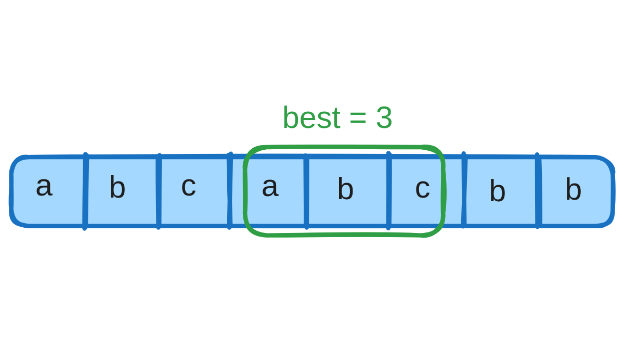>

In [ ]:
def longest_unique(s):
  tail = 0
  env = set()
  best_eat = 0

  for head, eatable in enumerate(s):
    while eatable in env:
      env.remove(s[tail])
      # did below mistake
      # seen.remove(char)
      tail += 1
    env.add(eatable)
    best_eat = max(best_eat, head - tail + 1)

  return best_eat

longest_unique(s="abcabcbb")

3

## Pattern 3 — Sliding Window + Frequency Constraint

**Importance:** ★★★★★

### Story
You’re hiring a team of up to k contractors to fill gaps in your crew. Your crew has a star player — the most common character — and everyone else needs to be replaced to match them. As long as the number of replacements needed stays within budget (k), you keep the window open and keep growing it. The moment you’d need more than k replacements to make the window uniform, you slide the left side forward to release one worker. The key is tracking the most frequent character in the window — that’s your anchor. The rest of the window is just slots you’re allowed to change. Every valid window size is a candidate for the best answer.

### When to Use
*   Longest substring problems that involve replacements or character limits
*   Checking if a permutation or anagram exists in a string
*   Any problem where the window validity depends on character counts
*   Subarray or substring problems with a frequency-based condition

### Core Idea
Keep a frequency map of the characters in the window. Every time the window violates the constraint, move the left pointer forward and update the map until things are valid again.

### Pitfalls
*   Shrinking the window without updating the frequency map
*   Getting the constraint check wrong --- test it on a small example by hand first
*   Mixing this up with the fixed-size window --- the key difference is that size here is not predetermined

### Mini Example
**Example:** `s = 'aababb'` → longest repeating character replacement is `'aaaa'`, length 4
where `k = 1`.

![][image1]

[image1]: <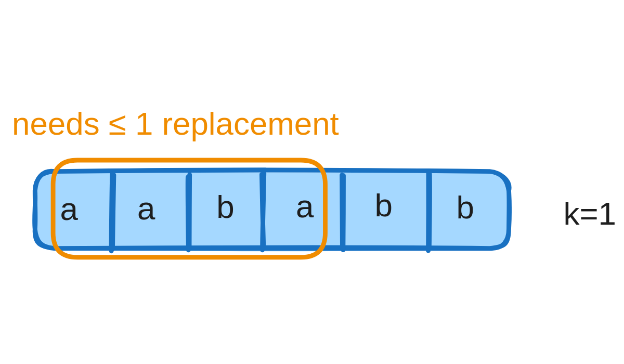>

In [ ]:
def longest_repeating_char(env:str, k:int) -> int:
  freq = {}
  tail = 0
  best = 0
  max_freq = 0

  for head, eatable in enumerate(env):
    freq[eatable] = freq.get(eatable, 0) + 1
    max_freq = max(max_freq, freq[eatable])

    while (head - tail + 1) - max_freq > k:
      freq[env[tail]] -= 1
      head += 1
    best = max(best, head - tail + 1)

  return best

longest_repeating_char(s="aababb", k=1)


4

## Pattern 4 — Two Pointers (Opposite Ends)

**Importance:** ★★★★★

### Story
Two people are walking toward each other on a number line — one starting at the smallest value, one at the largest. At every step they check: does their combined value hit the target? If the total is too big, the person on the right steps inward — they can only get smaller. If the total is too small, the person on the left steps inward — they can only get bigger. Because the array is sorted, every single move rules out an entire row of dead-end pairings. They keep walking toward each other, eliminating impossibilities with every step, until they either find the answer or meet in the middle and confirm it isn’t there.

### When to Use
*   Sorted arrays where you’re looking for a pair matching a condition
*   Pair-sum problems --- find two numbers that hit a target
*   Any problem where you can eliminate candidates from both ends simultaneously

### Core Idea
Left pointer starts at index 0, right pointer at the last index. Sum them. Too small? Advance left. Too big? Pull right back. Keep going until they meet.

### Pitfalls
*   Using this on an unsorted array --- it only works because sorting guarantees directionality

### Mini Example
**Example:** `arr = [1,2,3,4,6]`, `target = 6` → indices `[1,3]` (2 + 4 = 6).

![][image1]

[image1]: <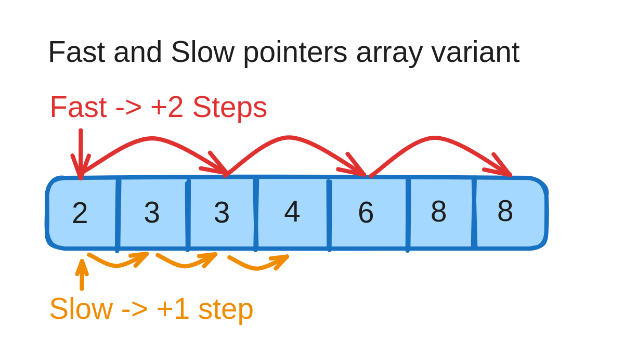>

In [ ]:
def two_sum_sorted(arr:list, target:int)->list:
  tail = 0
  head = len(arr) - 1
  while tail < head:
    curr_sum = arr[head] + arr[tail]
    if curr_sum == target:
      return [tail, head]
    elif curr_sum < target:
      tail += 1
    else:
      head -=1
  return None

two_sum_sorted(arr=[1,2,3,4,6], target=6)

[1, 3]

In [ ]:
def pair_sum(arr:list, target:int)->list:
  for i in range(len(arr)):
    curr = arr[i]
    arrSlice = arr[i+1:]
    diff_for_target = target - curr
    if diff_for_target in arrSlice:
      return [i, arrSlice.index(diff_for_target) + i + 1]
  return None


pair_sum(arr=[1,2,3,4,6], target=6)

[1, 3]

## Pattern 5 — Two Pointers (Fast–Slow)

**Importance:** ★★★★★

### Story
Two runners set off from the same starting line. One jogs — one step at a time. The other sprints — two steps to every one. On a straight track, the sprinter hits the finish line first and that’s that. But on a circular track with no exit, the sprinter keeps looping. And because they’re moving at different speeds on the same loop, they will eventually land on the same spot at the same time. When they meet, you’ve confirmed the loop exists. To find the middle of a straight list, you use the same trick: when the sprinter hits the end, the jogger is standing exactly at the halfway point.

### When to Use
*   Detecting cycles in linked lists
*   Finding the middle of a linked list
*   Cycle-related problems in sequences

### Core Idea
Move slow one step, fast two steps. If they ever land on the same node, you found a cycle. To find the middle, just stop when fast hits null --- slow will be at the midpoint.

### Pitfalls
*   Advancing fast without checking `fast && fast.next` first — this crashes on non-cyclic lists
*   Getting stuck in an infinite loop by not advancing both pointers on every iteration

### Mini Example
**Example:** `1 → 2 → 3 → 4 → 2` (cycle) → returns true; a non-cyclic list returns false.

![][image1]

[image1]: <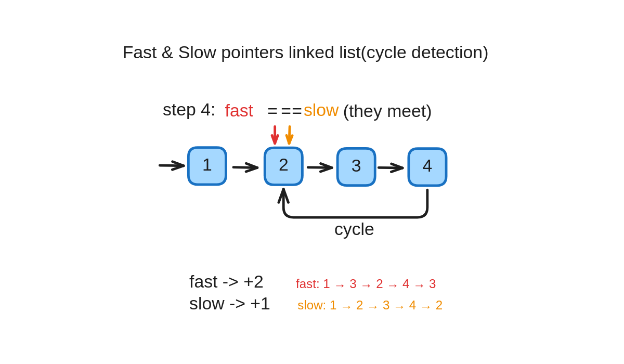>

In [ ]:
class Node:
  def __init__(self, value):
    self.value = value
    self.next = None
# -------------------------
# Example 1: Cyclic List

# 1 -> 2 -> 3 -> 4

#      ^         |

#      |_________|

n1 = Node(1)
n2 = Node(2)
n3 = Node(3)
n4 = Node(4)
n1.next = n2
n2.next = n3
n3.next = n4
n4.next = n2     # Creates a cycle

In [ ]:
def has_cycle(head:Node)->bool:
  slow = fast = head
  while fast and fast.next:
    slow = slow.next
    fast = fast.next.next
    if slow == fast:
      return True
  return False
has_cycle(n1)

True

## Pattern 6 — Prefix Sum

**Importance:** ★★★★

### Note:
In practice, we often use an extra prefix element `P[0] = 0`.
This allows easy range sum queries:
*   `P[i] = sum of A[0..i-1]`
*   `rangeSum(l, r) = P[r+1] - P[l]`

The diagram above shows the running sum intuition.

### Story
You’re hiking a trail and someone planted mile markers every few steps — not just showing your current position, but your total distance from the trailhead. Want to know the distance between marker 3 and marker 7? Subtract. No walking required, no recounting. That’s prefix sum. You pay one pass up front to plant all the markers. After that, every range query — no matter how many you have — costs exactly one subtraction. The power is in the precomputation. The trick that catches people is the off-by-one: `prefix[i]` stores the sum of everything before index `i`, so a leading zero makes every query clean and consistent.

### When to Use
*   Fast range sum queries without recomputing
*   Counting subarrays that hit a specific sum, often paired with a hash map
*   Turning `O(n²)` nested sum loops into a single `O(n)` pass

### Core Idea
Build an array where `prefix[i]` stores the sum of `arr[0]` through `arr[i-1]`. The sum of any subarray `[L, R]` becomes `prefix[R+1]` minus `prefix[L]` — a single subtraction.

### Pitfalls
*   Off-by-one errors --- it’s easy to mix up whether `prefix[i]` includes `arr[i]` or not. Use a leading 0 and be consistent.

### Mini Example
**Example:** `arr = [2,3,7,5]`, `prefix = [0,2,5,12,17]`. Sum of `[1,2]` = 10 via `prefix[3] - prefix[1]`.

![][image1]

[image1]: <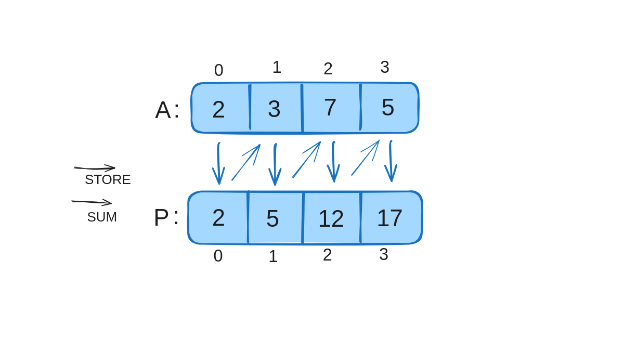>

In [ ]:
def prefix_sum(arr:list, sum_for:list):
  # compute prefix array
  # get range from sum_for
  # sum = head + 1 - tail
  prefix = [0]
  for i in range(len(arr)):
    prefix.append(prefix[i] + arr[i])
  print(prefix)
  x, y = sum_for
  return prefix[y+1] - prefix[x]

prefix_sum(arr=[2,3,7,5], sum_for=[1,2])


[0, 2, 5, 12, 17]


10

## Pattern 7 — Kadane's Algorithm

**Importance:** ★★★★

### Story
You continuously decide whether to extend a subarray or start fresh. This converts nested subarray checks into a single pass.

### When to Use
*   Maximum subarray sum
*   Problems involving the best contiguous range
*   Circular array variations

### Core Idea
`current_max = max(current_element, current_max + current_element)`

### Pitfalls
*   Forgetting negative-only arrays
*   Resetting at the wrong time

### Mini Example
**Example:** `nums = [-2,1,-3,4,-1,2,1,-5,4]` → maximum subarray sum is `6` (`[4,-1,2,1]`)

![][image1]

[image1]: <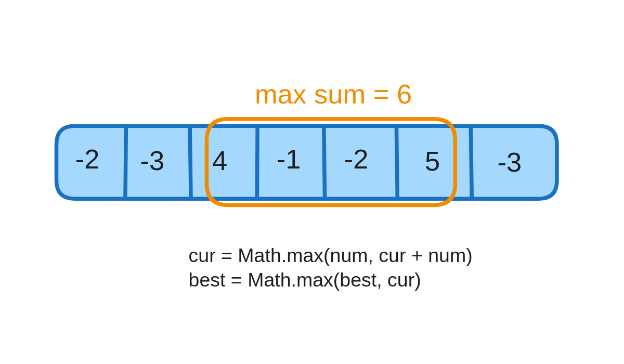>

In [ ]:
def max_subarray_sum(nums: list) -> int:
    if not nums:
        return 0

    max_so_far = nums[0]
    current_max = nums[0]

    for i in range(1, len(nums)):
        current_max = max(nums[i], current_max + nums[i])
        max_so_far = max(max_so_far, current_max)

    return max_so_far

# Example Usage:
nums_example = [-2, 1, -3, 4, -1, 2, 1, -5, 4]
print(f"The maximum subarray sum for {nums_example} is: {max_subarray_sum(nums_example)}")

## Pattern 8 — Hash Map

**Importance:** ★★★★

### Story
Think of a hash map as a counting dictionary. You toss items into a bag and maintain counts of each type.

### When to Use
*   Anagram checks
*   Frequency-based conditions
*   Finding majority elements, duplicates, etc.

### Core Idea
Use an object or a Map to count occurrences, then query those counts to apply conditions.

### Pitfalls
*   Not initializing missing keys correctly
*   Forgetting to decrement when using counts bidirectionally

### Mini Example
**Example:** `'xyyz'` and `'yxzy'` → same frequency of each character → anagrams.

![][image1]

[image1]: <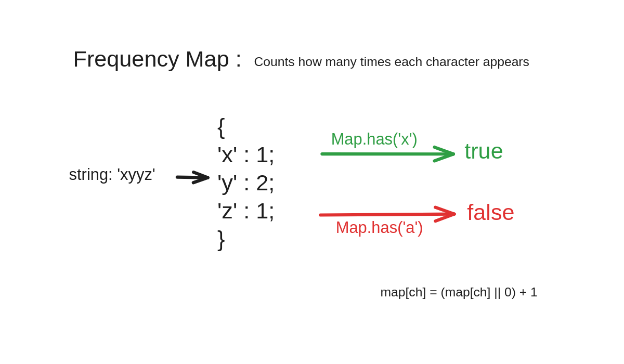>

In [ ]:
from collections import Counter
# from collection import defaultdict
def is_anagram(str1, str2):
  freq = Counter(str1)
  for char in str2:
    if freq[char] == 0:
      return False
    freq[char] -= 1
  return True

is_anagram(str1="xyyz", str2="yxzy")

True

## Pattern 9 — Basic Stack

**Importance:** ★★★★

### Story
A stack is like a stack of plates—last in, first out. Great for tracking nested structure.

### When to Use
*   Parentheses validation
*   Undo operations
*   Evaluating expressions (like RPN)

### Core Idea
Push when you see an opener; pop and check when you see a closer.

### Pitfalls
*   Returning true too early before verifying the stack is empty
*   Forgetting edge cases like empty strings

### Mini Example
**Example:** `s = '(())[]'` → valid; `s = '([)]'` → invalid.

![][image1]

[image1]: <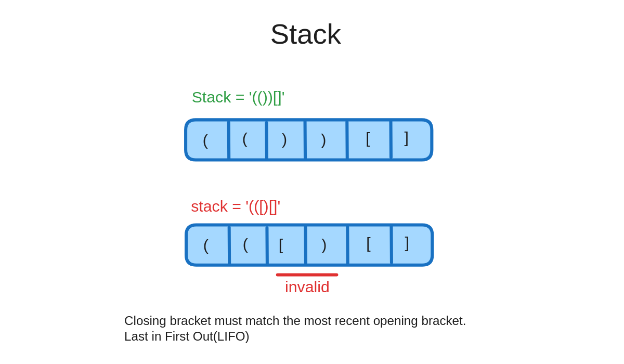>

In [ ]:
def isValid(s:str)->bool:
  pairs = {
      ')':'(',
      ']':'[',
      '}':'{'
  }
  stack = []
  for char in s:
    if char in pairs: # Check if the character is a closing bracket
      if not stack or stack.pop() != pairs[char]: # If stack is empty or top doesn't match
        return False
    else:
      stack.append(char) # It's an opening bracket, push it to stack
  return len(stack) == 0


isValid(s = '(())[]')


True

## Pattern 10 — Monotonic Stack

**Importance:** ★★★★★

### Story
A monotonic stack keeps its elements in increasing or decreasing order. This is perfect for problems like 'next greater element'. Imagine 6 kids standing in a line, and each kid has a height. Every kid asks the same question: "Looking at the kids behind me, who is the first kid taller than me?"

### When to Use
*   Next greater element
*   Daily temperatures
*   Largest rectangle in a histogram

### Core Idea
While the current element violates the stack's monotonic property, pop from the stack and resolve that index.

### Pitfalls
*   Keeping tracking of heights instead of indexes since there can be duplicate heights in the array that doesn't work
*   Forgetting to process the remaining stack after the main loop
*   Mixing up increasing vs decreasing configurations

### Mini Example
**Example:** `nums = [2, 7, 3, 5, 1, 6]` → next greater `=[7, -1, 5, 6, 6, -1]`.

![][image1]

[image1]: <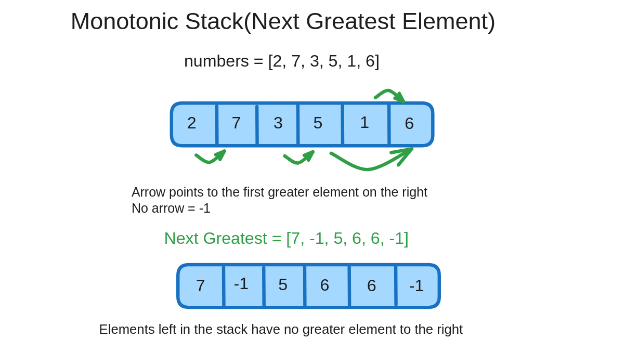>

In [ ]:
def next_greater(heights):
    n = len(heights)
    answer = [-1] * n      # everyone starts as "nobody taller found yet"
    waiting_list = []      # this is our notepad — holds INDICES of kids still waiting

    for i in range(n):
        # i = the current kid we're looking at (walking down the line)

        # Keep checking: is current kid TALLER than the last kid on our waiting list?
        while waiting_list and heights[i] > heights[waiting_list[-1]]:
            # Yes! That waiting kid finally found their answer.
            waiting_kid_index = waiting_list.pop()   # cross them off the list
            answer[waiting_kid_index] = heights[i]   # record who's taller than them

        # Either the list is empty, or the last kid on it is taller than us.
        # Either way, WE now join the waiting list.
        waiting_list.append(i)

    return answer


heights = [2, 7, 3, 5, 1, 6]
print(next_greater(heights))

[7, -1, 5, 6, 6, -1]


## Pattern 11 — Reverse Linked List

### Story
Picture a treasure hunt: cards on a table, each with a clue and an arrow pointing to the next card. Card A → Card B → Card C → Card D → end.

To reverse it, you walk down the cards one at a time and flip each arrow to point backward instead of forward. The catch: once you flip an arrow, you lose track of what came next — so before flipping, you peek ahead and remember the next card first.

So for each card:

*   Remember the next card (sticky note).
*   Flip this card's arrow to point at the previous card.
*   Move to the next card (from the sticky note).
*   Repeat until no cards are left.

### When to Use
*   Reversing an entire list
*   As a subroutine in more complex problems (like reversing in k-groups)

### Core Idea
Iterate with three pointers: prev, curr, next. Flip curr.next to prev, then move all three forward.

### Pitfalls
*   Losing the next pointer before reassigning
*   Not returning the new head (prev at the end)

### Mini Example
**Example:** `Card A → Card B → Card C → Card D → end.` becomes `Card D → Card C → Card B → Card A → end.`

![][image1]

[image1]: <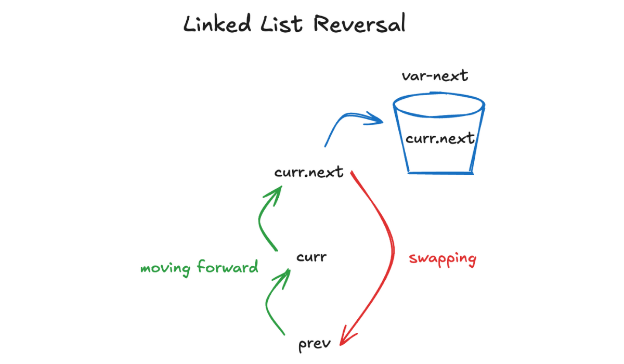>

In [ ]:
def list_reversal(head):
  next = None
  prev = None
  curr = head

  while(curr):
    next = curr.next
    curr.next = prev
    prev = curr
    curr = next
  return prev

def print_list(head):
    curr = head
    while curr:
        print(curr.data, end=" -> ")
        curr = curr.next
    print("None")

class Node:
  def __init__(self, data):
    self.data = data
    self.next = None

head = Node("A")
head.next = Node("B")
head.next.next = Node("C")
head.next.next.next = Node("D")

print("Original List",end=" ")
print_list(head)
head = list_reversal(head)
print("Reversed List",end=" ")
print_list(head)


Original List A -> B -> C -> D -> None
Reversed List D -> C -> B -> A -> None


## Pattern 12 — Merge Two Sorted Lists

### Story
Think of two sorted lanes of traffic merging into a single sorted lane. You always pick the smaller front car.

### When to Use
*   Merging two sorted lists
*   Base for 'merge k sorted lists' and merge sort on linked lists

### Core Idea
Use a dummy head and a tail pointer. Repeatedly choose the smaller node from the two lists and advance that list.

### Pitfalls
*   Forgetting to attach the remaining nodes after one list finishes

### Mini Example
**Example:** `[1,3,5]` merged with `[2,4,6]` → `[1,2,3,4,5,6]`.

![][image1]

[image1]: <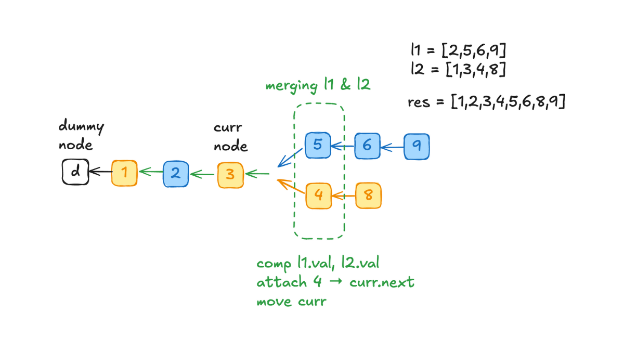>

In [ ]:
class Node:
  def __init__(self, data):
    self.data = data
    self.next = None

def print_nodes(head):
  while(head):
    print(head.data, end="-->")
    head = head.next
  print("None")

l1 = Node(2)
l1.next = Node(5)
l1.next.next = Node(6)
l1.next.next.next = Node(9)

print("l1 :", print_nodes(l1))

l2 = Node(1)
l2.next = Node(3)
l2.next.next = Node(4)
l2.next.next.next = Node(8)
print('Final nodes')
print_nodes(l2)

def merge_sorted_lists(l1, l2):
  dummy = Node(-1)
  tail = dummy

  while(l1 and l2):
    if(l1.data < l2.data):
      tail.next = l1
      l1 = l1.next
    else:
      tail.next = l2
      l2 = l2.next
    tail = tail.next
  tail.next = l1 or l2
  return dummy.next

print('Final nodes')
print_nodes(merge_sorted_lists(l1, l2))

2-->5-->6-->9-->None
l1 : None
1-->3-->4-->8-->None
l2 : None
1-->2-->3-->4-->5-->6-->8-->9-->None
Final nodes None


## Pattern 13 — Fast–Slow Linked List

**Importance:** ★★★★★

### Story
Picture a turtle and a rabbit running around a circular track. The turtle moves one step per turn, the rabbit moves two. If the track forms a loop, the rabbit will eventually catch the turtle. This simple intuition helps detect cycles, find the middle of a list, or determine intersection points.

### When to Use
*   Detecting linked list cycles
*   Finding the middle node
*   Cycle entry detection (Floyd’s algorithm)

### Core Idea
Use two pointers: `slow = slow.next` and `fast = fast.next.next`. If they ever meet, a cycle exists.

### Pitfalls
*   Not checking `fast && fast.next` before advancing
*   Confusing the meeting point with the cycle start (requires a second phase)

### Mini Example
**Example:** In `1→2→3→4→2` (cycle), slow and fast eventually meet.

![][image1]

[image1]: <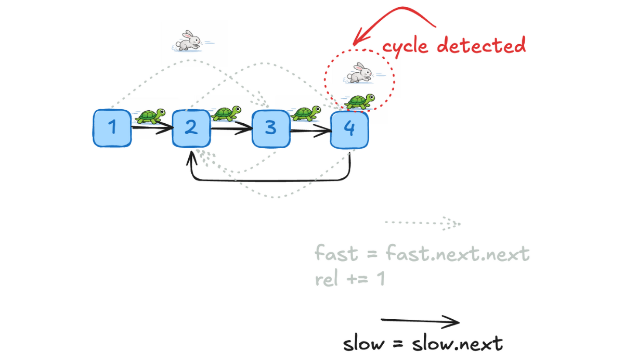>

In [ ]:
def hasCycle(head):
  slow = fast = head
  while(fast and fast.next):
    slow = slow.next
    fast = fast.next.next
    if slow == fast:
      return True
  return False

class Node:
  def __init__(self, val):
    self.val = val
    self.next = None

a = Node(1)
b = Node(2)
c = Node(3)
d = Node(4)
e = Node(5)

a.next = b
b.next = c
c.next = d
d.next = e
e.next = b

print(hasCycle(a))



True


## Pattern 14 — Tree DFS — Post-Order Combine

**Importance:** ★★★★★

### Story
Think of climbing a tree and gathering results from each child before deciding the parent. This bottom‑up strategy is perfect when a parent’s value depends on its children’s values, such as computing height, valid BST checks, path sums, or diameter.

### When to Use
*   Tree height/depth calculations
*   Balanced tree checks
*   Aggregating results from subtree computations

### Core Idea
Process left subtree → right subtree → compute and return value for the current node.

### Pitfalls
*   Forgetting the null base case
*   Returning wrong values when combining child results

### Mini Example
**Example:** A balanced tree with nodes `[3,9,20,15,7]` has depth 3.

![][image1]

[image1]: <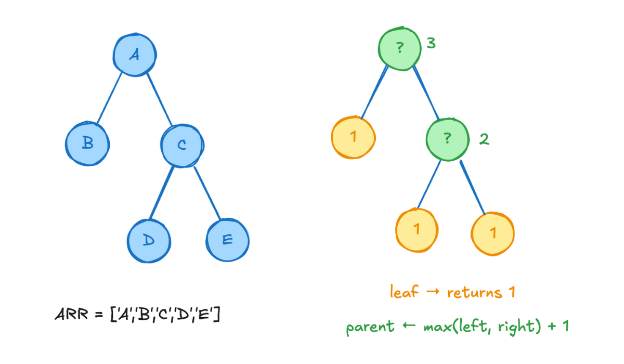>

In [ ]:
def maxDepth(root):
  if not root: return 0
  return 1 + max(maxDepth(root.left), maxDepth(root.right))

class Tree:
  def __init__(self, value):
    self.value = value
    self.right = None
    self.left = None

A = Tree("A")
B = Tree("B")
C = Tree("C")
D = Tree("D")
E = Tree("E")

A.right = C
A.left = B
C.left = D
C.right = E

print(maxDepth(A))


3


In [ ]:
def dfs_iterative(tree):
    if tree is None:
        return []
    result = []
    stack = [tree]

    while stack:
        node = stack.pop()          # pop from the END now
        result.append(node.data)
        if node.left is not None:
            stack.append(node.left)
        if node.right is not None:
            stack.append(node.right)

    return result

class Tree:
  def __init__(self, data):
    self.data = data
    self.right = None
    self.left = None

A = Tree("A")
B = Tree("B")
C = Tree("C")
D = Tree("D")
E = Tree("E")

A.right = C
A.left = B
C.left = D
C.right = E
dfs_iterative(A)

['A', 'C', 'E', 'D', 'B']

## Pattern 15 — Binary Tree Path Pattern

**Importance:** ★★★★★

### Story
Imagine walking down a tree carrying a bag of coins (target).

At every node:
*   You pay the node’s value
*   If you reach a leaf, check: Is my bag exactly empty?

Pattern is particularly useful for problems that require tracking values from root to leaf. Each recursive call carries path state downward.

### When to Use
*   Root-to-leaf problems
*   Path sum calculations
*   Tree path construction

### Core Idea
*   Pass path or sum into recursion.
*   Check the condition at leaf nodes.

### Pitfalls
*   Confusing this with generic DFS
*   Forgetting to backtrack the path state

### Mini Example
Path Sum, All Paths, Max Path Sum

![][image1]

[image1]: <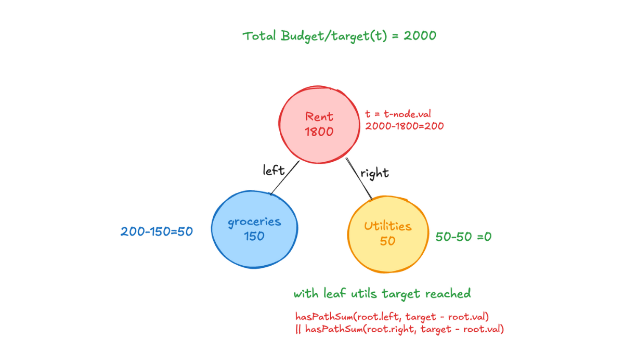>

In [ ]:
def hasPathSum(root, target):
  if not root: return False
  if not root.left and not root.right: return target == root.val
  return hasPathSum(root.left, target - root.val) or hasPathSum(root.right, target - root.val)

class Tree:
  def __init__(self, val):
    self.val = val
    self.left = None
    self.right = None

root = Tree(1800)
root.right = Tree(50)
root.left = Tree(150)

hasPathSum(root, 1851) # False
#hasPathSum(root, 1850) # True
#hasPathSum(root, 1950) # True



False

## Pattern 16 — Tree BFS — Level Order Traversal

**Importance:** ★★★★★

### Story
Imagine exploring a building floor by floor. BFS visits all nodes at one level before moving to the next. This gives a natural layered view of a tree, making BFS perfect when levels matter.

### When to Use
*   Level order traversal
*   Right/left side view of a tree
*   Zigzag level order

### Core Idea
*   Use a queue, process nodes level by level, and record each layer as a list.

### Pitfalls
*   Forgetting to reset 'level' list each iteration
*   Not handling empty root edge case

### Mini Example
Example: Tree `[3,9,20,null,null,15,7]` → `[[3],[9,20],[15,7]]`.

![][image1]

[image1]: <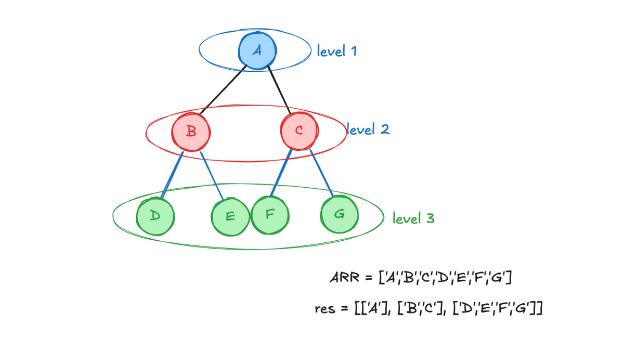>

In [ ]:
def levelOrder(tree):
  if tree is None:
    return
  queue = []
  result = []
  queue.append(tree)
  while len(queue) > 0:
    node = queue.pop(0)
    result.append(node.data)
    if node.left is not None:
      queue.append(node.left)
    if node.right is not None:
      queue.append(node.right)
  return result


class Tree:
  def __init__(self, data):
    self.data = data
    self.left = None
    self.right = None

A = Tree("A")
B = Tree("B")
C = Tree("C")
D = Tree("D")
E = Tree("E")
F = Tree("F")
G = Tree("G")

A.left = B
A.right = C
B.left = D
B.right = E
C.left = F
C.right = G

levelOrder(A)


['A', 'B', 'C', 'D', 'E', 'F', 'G']

In [ ]:
def levelOrderLevels(tree):
    if tree is None:
        return []
    result = []
    queue = [tree]

    while queue:
        level_size = len(queue)     # how many nodes are in THIS level
        current_level = []          # collect this level's data here

        for _ in range(level_size):
            node = queue.pop(0)
            current_level.append(node.data)
            if node.left is not None:
                queue.append(node.left)
            if node.right is not None:
                queue.append(node.right)

        result.append(current_level)

    return result

print(levelOrderLevels(A))

[['A'], ['B', 'C'], ['D', 'E', 'F', 'G']]


### Note

There is no way of doing it recursively directly without levels.

So the real rule underneath your generalization is: BFS wants FIFO (first-in-first-out) → queue. DFS wants LIFO (last-in-first-out) → stack, and recursion gives you a stack automatically.

In [ ]:
def levelOrderRecLevels(tree, level=0, result=None):
    if result is None:
        result = []
    if tree is None:
        return result
    if len(result) == level:
        result.append([tree.data])
    else:
        result[level].append(tree.data)
    levelOrderRecLevels(tree.left, level + 1, result)
    levelOrderRecLevels(tree.right, level + 1, result)
    return result

print(levelOrderRecLevels(A))

[['A'], ['B', 'C'], ['D', 'E', 'F', 'G']]


## Pattern 17 — Graph BFS — Shortest Path (Unweighted)

**Importance:** ★★★★★

### Story
Imagine S is a person who hears a secret. S immediately tells everyone standing right next to them — A, B, and C — that takes "1 step." Then A, B, and C each tell everyone they know that hasn't heard yet — that's "2 steps." This keeps spreading outward in waves, one step at a time, until everyone's heard it.

### When to Use
*   Shortest path in unweighted graphs
*   Word ladder problems
*   Minimum jumps or transformations

### Core Idea
Use BFS from the source; maintain a visited set and record distances.

### Pitfalls
*   Not marking visited early (causes repeated processing)
*   Using BFS on weighted graphs (use Dijkstra instead)

### Mini Example
**Example:** BFS ensures the first time you reach a node, it is via the shortest route.

![][image1]

[image1]: <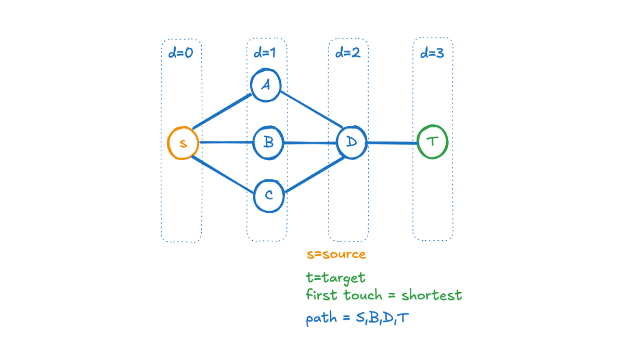>

In [ ]:
graph = {
    'S':  ['A', 'B', 'C'],
    'A': ['S', 'D'],
    'B': ['S', 'D'],
    'C': ['S', 'D'],
    'D': ['A', 'B', 'C', 'T'],
    'T': ['D']
}

def shortestPath(graph, start, target):
    # "seen" = everyone who has already heard the rumor.
    # We add 'start' immediately, since the source already knows their own secret.
    seen = set([start])

    # "queue" holds people waiting to spread the rumor to their neighbors.
    # Each entry is [person, path_taken_to_reach_them]
    # We store the FULL PATH now, not just the distance, so we can
    # reconstruct exactly how the rumor traveled.
    queue = [[start, [start]]]

    while len(queue):
        # Pop the next person in line (FIFO -> queue -> BFS)
        vertex, path = queue.pop(0)

        # If this person is who we're looking for, we're done.
        # Because BFS spreads in waves, the FIRST time we reach the
        # target is guaranteed to be via the SHORTEST path.
        if vertex == target:
            return path

        # Tell everyone this person knows about the rumor
        for neighbor in graph[vertex]:
            if neighbor not in seen:
                # neighbor's path = everything in current path + neighbor themself
                queue.append([neighbor, path + [neighbor]])
                seen.add(neighbor)  # mark as heard so we never re-visit

    # If we empty the queue without finding target, no path exists
    return None


result = shortestPath(graph, 'S', 'T')
print(result)

['S', 'A', 'D', 'T']


## Pattern 18 — Multi-Source BFS

**Importance:** ★★★★★

### Story
Imagine a building catches fire, but not from one spot — several separate fires break out at the same time, in different rooms. You want to know: how many minutes until the fire reaches every room in the building?

If you only started the timer from one fire, you'd get the wrong answer for rooms that are actually closer to a different fire. The real spread time for any room is "however long it takes the nearest fire to reach it."

The trick: instead of starting BFS from one point, you start it from ALL the fires at once, in the same starting wave.

Picture it like this — at time 0, every burning room is already "on the queue," all together, all treated as distance 0. Then the fire spreads outward from all of them simultaneously, one step at a time. Whichever fire reaches a room first "wins" that room's distance — which is exactly what you want, since fire doesn't care which source it came from, only which one got there fastest.

Mapping this to code: it's almost identical to regular BFS — the only difference is how you initialize the queue. Instead of queue = [[start, 0]] with one starting point, you seed the queue with all starting points at once, all at distance 0:

### When to Use
*   Grid problems
*   Minimum time or distance from multiple sources
*   Spread simulations

### Core Idea
Push all sources into the queue initially.

### Pitfalls
*   Forgetting to mark visited early
*   Running BFS separately instead of combined

### Mini Example
Rotting Oranges, Walls and Gates

![][image1]

[image1]: <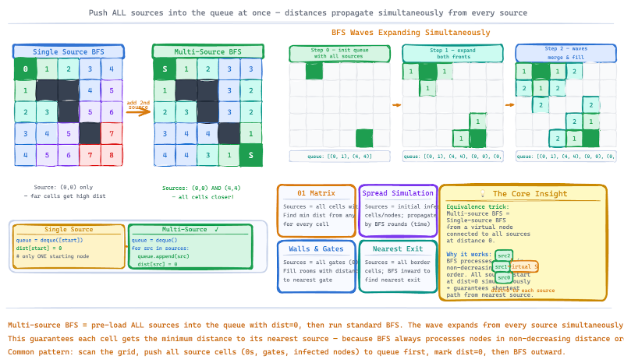>

In [ ]:
from collections import deque

def multiSourceBFS(graph, sources):
    queue = deque()
    seen = set()

    # seed the queue with ALL fires at once, all starting at distance 0
    for s in sources:
        queue.append((s, 0))
        seen.add(s)

    distances = {}

    while queue:
        node, dist = queue.popleft()
        distances[node] = dist
        for neighbor in graph[node]:
            if neighbor not in seen:
                seen.add(neighbor)
                queue.append((neighbor, dist + 1))

    return distances

# Sample graph: rooms in a building, connected to adjacent rooms
rooms = {
    'A': ['B'],
    'B': ['A', 'C', 'E'],
    'C': ['B', 'D'],
    'D': ['C', 'F'],
    'E': ['B', 'F'],
    'F': ['D', 'E', 'G'],
    'G': ['F']
}

# Fires start in room A and room G at the same time
fires = ['A', 'G']

print(multiSourceBFS(rooms, fires))

{'A': 0, 'G': 0, 'B': 1, 'F': 1, 'C': 2, 'E': 2, 'D': 2}


## Pattern 19 — Graph DFS

**Importance:** ★★★★★

### Story
DFS dives deep before backtracking. It's like exploring every hallway in a maze until you hit a dead end, then retracing steps.

### When to Use
*   Detecting connected components
*   Cycle detection
*   Exploring graph structures

### Core Idea
Mark a node as visited, recursively explore neighbors.

### Pitfalls
*   Forgetting to maintain a visited set, causing infinite loops
*   Stack overflow in very deep graphs without iteration

### Mini Example
**Example:** Counting connected components by running DFS from every unseen node.

![][image1]

[image1]: <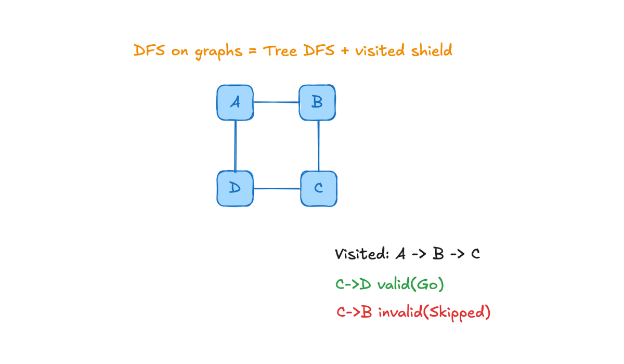>

In [ ]:
graph = {
    'S': ['A', 'B', 'C'],
    'A': ['S', 'D'],
    'B': ['S', 'D'],
    'C': ['S', 'D'],
    'D': ['A', 'B', 'C', 'T'],
    'T': ['D']
}

def dfs_recursive(graph, node, seen=None):
    if seen is None:
        seen = set()

    seen.add(node)          # mark this room as visited
    print(node)              # "visit" it (in this case, just print)

    for neighbor in graph[node]:
        if neighbor not in seen:
            dfs_recursive(graph, neighbor, seen)   # dive deeper down this tunnel

    return seen


dfs_recursive(graph, 'S')

S
A
D
B
C
T


{'A', 'B', 'C', 'D', 'S', 'T'}

In [ ]:
graph = {
    'S': ['A', 'B', 'C'],
    'A': ['S', 'D'],
    'B': ['S', 'D'],
    'C': ['S', 'D'],
    'D': ['A', 'B', 'C', 'T'],
    'T': ['D']
}

def dfs_iterative(graph, start):
    seen = set([start])
    stack = [start]
    order = []

    while stack:
        node = stack.pop()      # pop from the END = stack behavior = DFS
        order.append(node)
        for neighbor in graph[node]:
            if neighbor not in seen:
                seen.add(neighbor)
                stack.append(neighbor)

    return order


print(dfs_iterative(graph, 'S'))

['S', 'C', 'D', 'T', 'B', 'A']


The bigger takeaway: DFS doesn't guarantee one universal order — it only guarantees "go deep before wide." The exact order depends on implementation details like which neighbor you check first, so don't be surprised if two "correct" DFS implementations give different-looking (but equally valid) outputs.

## Pattern 20 — Grid BFS/DFS — The Islands Pattern

**Importance:** ★★★★★

### Story
Picture a satellite photo turned into a grid of pixels. Each pixel is either water (0) or land (1). Land pixels that touch each other (up/down/left/right) belong to the same island. You want to count how many separate islands exist.

The approach: walk through every cell in the grid. Whenever you find an unvisited land cell, that's a new island — increment your count by 1, then DFS outward from there, "flooding" and marking every connected land cell as visited so you never count it again. Like dropping dye at one spot on an island and watching it spread to every connected patch of land, but not across water.

### When to Use
*   Number of islands
*   Flood fill
*   Connected region detection

### Core Idea
Perform DFS/BFS from each unvisited 'land' cell, marking the entire connected region.

### Pitfalls
*   Not marking visited before recursion → repeated work
*   Not checking boundaries

### Mini Example
**Example:** In a 4×5 grid, DFS floods each island once, counting distinct regions.

![][image1]

[image1]: <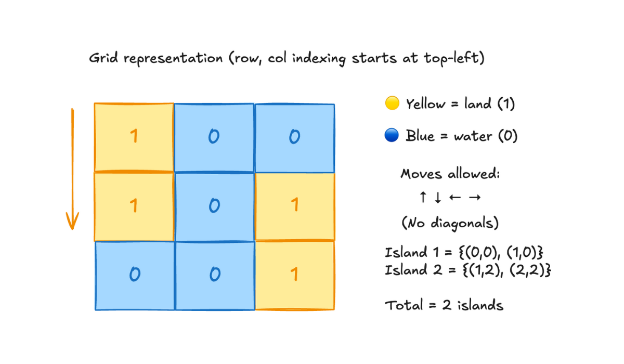>

In [ ]:
def numIslands(grid):
    if not grid:
        return 0

    rows = len(grid)
    cols = len(grid[0])
    seen = set()

    def dfs(r, c):
        # stop if out of bounds, already seen, or water
        if (r < 0 or r >= rows or c < 0 or c >= cols
                or (r, c) in seen or grid[r][c] == 0):
            return
        seen.add((r, c))            # mark this land cell as visited
        dfs(r + 1, c)                # flood down
        dfs(r - 1, c)                # flood up
        dfs(r, c + 1)                # flood right
        dfs(r, c - 1)                # flood left

    islands = 0
    for r in range(rows):
        for c in range(cols):
            if grid[r][c] == 1 and (r, c) not in seen:
                islands += 1          # found a brand new island
                dfs(r, c)              # flood-fill the whole island so we don't recount it

    return islands


grid = [
    [1, 1, 0, 0, 0],
    [1, 1, 0, 0, 1],
    [0, 0, 0, 0, 1],
    [0, 0, 1, 0, 0]
]

print(numIslands(grid))

3


## Pattern 21 — Topological Sort

**Importance:** ★★★★★

### Story
Think about getting a college degree. Some courses require others first — you can't take "Advanced Calculus" before "Calculus 1." If you drew every course as a node, and drew an arrow from each course to the course that depends on it, you'd get a DAG (Directed Acyclic Graph — "directed" means arrows only go one way, "acyclic" means no loops, since a course can't secretly require itself through a chain).

Topological sort answers: "what's a valid order to take all these courses in, so I never take something before its prerequisite?"

The approach (Kahn's algorithm — BFS-based): figure out how many prerequisites each course has (its "in-degree"). Start with any course that has zero prerequisites — you can take that one right away. Take it, then for every course that depended on it, reduce their prerequisite count by one, since you just satisfied one of their requirements. Any course that hits zero remaining prerequisites is now ready to take too. Repeat until everything's scheduled.

This is the same wave-spreading BFS idea as the rumor and the fire — instead of "who's heard the rumor," it's "whose prerequisites are all satisfied."

### When to Use
*   Course scheduling problems
*   Dependency resolution
*   Ordering tasks with prerequisites

### Core Idea
Compute in-degree of each node, push nodes with zero in-degree into a queue, and process until empty.

### Pitfalls
*   Forgetting to detect cycles (when result size < nodes count)
*   Not computing in-degree correctly

### Mini Example
**Example:** Course prerequisites represented as a DAG can be ordered via topological sort.

![][image1]

[image1]: <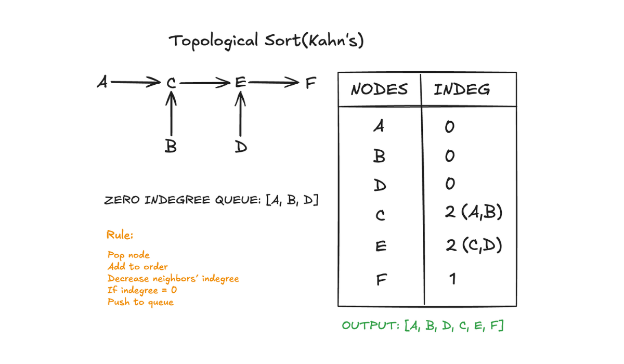>

In [ ]:
from collections import deque

def courseOrder(numCourses, prerequisites):
    # prerequisites: list of [course, prereq] pairs, meaning "prereq must come before course"
    graph = {i: [] for i in range(numCourses)}
    in_degree = {i: 0 for i in range(numCourses)}  # how many prereqs each course still needs

    for course, prereq in prerequisites:
        graph[prereq].append(course)   # prereq points TO the course that depends on it
        in_degree[course] += 1          # that course now has one more prereq to satisfy

    # start with every course that has ZERO prerequisites — ready to take now
    queue = deque([c for c in in_degree if in_degree[c] == 0])
    order = []

    while queue:
        course = queue.popleft()
        order.append(course)
        for next_course in graph[course]:
            in_degree[next_course] -= 1        # one prereq just got satisfied
            if in_degree[next_course] == 0:    # if ALL its prereqs are done, it's ready
                queue.append(next_course)

    # if we scheduled every course, return the order; otherwise there's a cycle (impossible schedule)
    return order if len(order) == numCourses else []


# Example: 4 courses, numbered 0-3
# [1, 0] means "course 1 requires course 0 first"
prerequisites = [[1, 0], [2, 0], [3, 1], [3, 2]]

print(courseOrder(4, prerequisites))

[0, 1, 2, 3]


## Pattern 22 — Union–Find (Disjoint Set)

### Importance: ★★★★★

### Story
Imagine you're at a big party, and people keep introducing pairs of friends to each other. Over time, groups of mutual friends form — everyone in a group is connected, directly or through a chain of introductions. Each group has one person you consider the "group representative" — doesn't matter who, just someone you can point to and say "ask them, they represent this whole friend group."

Now here's the cycle-detection idea: if someone tries to introduce two people who are already in the same friend group, that introduction is redundant — they were already connected some other way, so this new connection creates a loop back to the same group.

That's exactly what Union-Find detects in a graph. Each connected component (group of nodes all linked together) has a representative ("parent"). For every edge in the graph, you ask: "are these two nodes already in the same group?" If yes, adding this edge would create a cycle. If no, you merge their groups together (union them) and move on

### When to Use
*   Cycle detection in undirected graphs
*   Grouping related components
*   Counting connected components

### Core Idea
Maintain `parent[]` and `rank[]`. Use path compression + union by rank for efficiency.

### Pitfalls
*   Not applying path compression → slow performance
*   Merging by value instead of representative parent

![][image1]

[image1]: <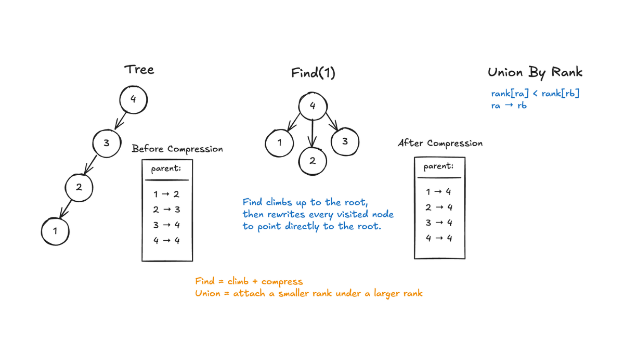>

In [ ]:
def find(parent, node):
    # walk up the chain until you reach the group's representative
    while parent[node] != node:
        node = parent[node]
    return node


def union(parent, node1, node2):
    # merge node2's whole group under node1's representative
    root1 = find(parent, node1)
    root2 = find(parent, node2)
    parent[root2] = root1


def hasCycle(n, edges):
    # start: everyone is their own representative (nobody's grouped with anyone yet)
    parent = {i: i for i in range(n)}

    for node1, node2 in edges:
        root1 = find(parent, node1)
        root2 = find(parent, node2)

        if root1 == root2:
            # they're already in the same group — this edge creates a cycle
            return True

        union(parent, node1, node2)

    return False


# Example: 4 nodes (0,1,2,3), edges forming a triangle plus one extra node
edges = [[0, 1], [1, 2], [2, 0], [2, 3]]

print(hasCycle(4, edges))

True


## Pattern 23 — Binary Search (Classic)

### Importance: ★★★★★

### Story
Binary search is like looking for a word in a dictionary: open to the middle and decide which half to search next.

### When to Use
*   Searching sorted arrays
*   Finding boundaries (first/last occurrence)
*   Any monotonic condition

### Core Idea
While (`lo <= hi`): check `mid`, decide which half to keep.

### Pitfalls
*   Infinite loops caused by wrong `mid` update
*   Incorrect boundary handling

### Mini Example
**Example:** `nums=[1,3,5,7,9]`, `target=7` → returns index 3.

![][image1]

[image1]: <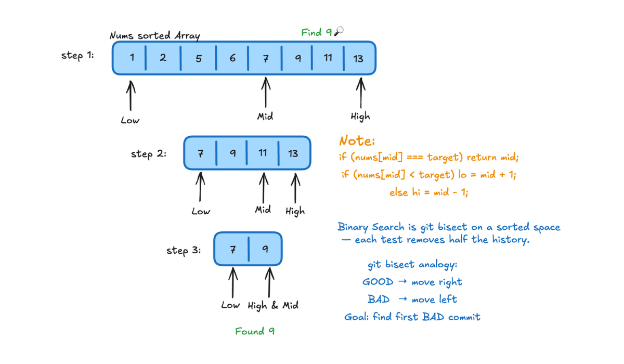>

In [ ]:
def binarySearch(nums, target)->int:
  head = 0
  tail = len(nums)
  while(head < tail):
    mid = (head + tail)//2
    curr = nums[mid]
    if curr == target:
      return mid
    elif curr > target:
      tail = mid
    else:
      head = mid - 1

  return -1

binarySearch(nums=[1,3,5,7,9], target=7)

3

## Pattern 24 — Binary Search on Answer

### Importance: ★★★★★

### Story
Koko has piles of bananas and a lazy zoo keeper only gives her h hours before checking on her. She eats at a fixed speed of k bananas per hour — but for any pile smaller than k, she still uses up a full hour on it (can't combine leftover time across piles). She wants to eat all the bananas within h hours, but she's not in a rush — she wants the slowest speed that still lets her finish in time, so she's not stuffing herself faster than necessary.

The question: what's the minimum eating speed k that lets Koko finish all piles within h hours?

Why is this "binary search on the answer" and not binary search on an array?

Here's the key insight: imagine you tried every possible speed, 1 banana/hr, 2/hr, 3/hr, and so on, and for each one you asked "does Koko finish in time at this speed?" You'd get a pattern like: No, No, No, ..., No, Yes, Yes, Yes, ... — once a speed works, every faster speed also works (eating faster never makes her slower to finish). That's a sorted yes/no pattern, exactly like a sorted array — so instead of searching through a list of numbers, you're binary searching through a range of possible speeds, looking for that flip point from "No" to "Yes."

Think of it like guessing a number between 1 and 1,000,000 with someone telling you "too low" or "too high" — same idea, except here "too low" means "Koko didn't finish in time."

### When to Use
*   Minimize the maximum value (e.g., allocate workloads)
*   Koko eating bananas
*   Finding minimum capacity or maximum feasible threshold

### Core Idea
Binary search the answer range; use a helper `check(mid)` to decide which half to search next.

### Pitfalls
*   Choosing the wrong answer range
*   Incorrect feasibility check

### Mini Example
**Example:** Koko chooses smallest `k` such that she finishes bananas within `h` hours.

![][image1]

[image1]: <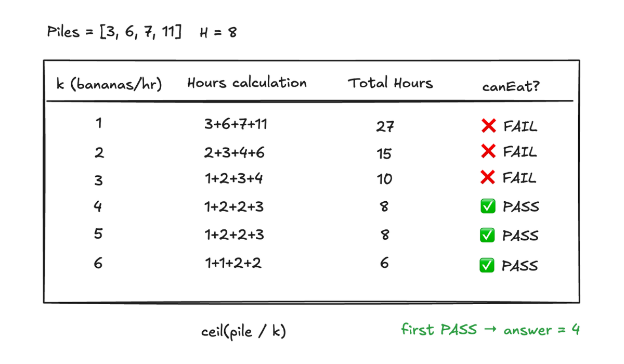>

In [ ]:
import math

def minEatingSpeed(piles, h):
    def hoursNeeded(speed):
        # for each pile, how many hours does it take at this speed?
        # math.ceil because even a small leftover still costs a full hour
        return sum(math.ceil(pile / speed) for pile in piles)

    low = piles[0]                  # slowest possible speed
    high = max(piles)        # fastest speed ever needed (finish biggest pile in 1 hour)

    while low < high:
        mid = (low + high) // 2   # candidate speed to test
        if hoursNeeded(mid) <= h:
            # this speed works! but maybe a slower speed also works — try smaller
            high = mid
        else:
            # too slow, Koko won't finish in time — need to go faster
            low = mid + 1

    return low


piles = [3, 6, 7, 11]
h = 8
print(minEatingSpeed(piles, h))

4


## Pattern 25 — Top-K Elements (Heap)

**Importance:** ★★★★★

### Story
finding the Top K most frequently searched products on an e-commerce site (like Amazon showing "trending searches"). This is exactly the kind of feature you'd build in a Spring Boot analytics service.

You have a stream of search query logs, and you want to show the "Top 5 Trending Searches" — a classic Top K problem.

### When to Use
*   K largest elements
*   Real-time ranking
*   Maintaining best K candidates

### Core Idea
Use a min-heap of size K. Insert every number; if size exceeds K, remove the smallest.

### Pitfalls
*   Using a max-heap complicates logic
*   Forgetting to pop when heap grows too large

### Mini Example
**Example:** `nums=[3,1,5,12,2,11], k=3` → top 3 = `[5,11,12]`.

![][image1]

[image1]: <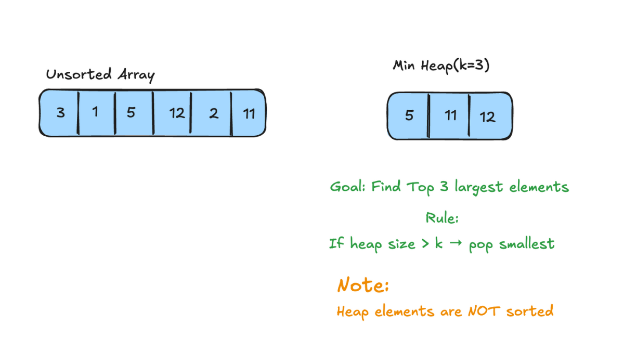>

In [ ]:
import heapq

def top_k_elements(nums, k):
    # Use a min-heap of size k
    min_heap = []

    for num in nums:
        heapq.heappush(min_heap, num)
        if len(min_heap) > k:
            heapq.heappop(min_heap)  # remove smallest, keep k largest

    # min_heap now contains the k largest elements (unsorted internally)
    return sorted(min_heap)


if __name__ == "__main__":
    nums = [3, 1, 5, 12, 2, 11]
    k = 3

    result = top_k_elements(nums, k)
    print(f"nums = {nums}, k = {k}")
    print(f"Top {k} elements = {result}")

nums = [3, 1, 5, 12, 2, 11], k = 3
Top 3 elements = [5, 11, 12]


## Pattern 26 — Ordered Set / Two Heaps (Median Pattern)

**Importance:** ★★★★★

### Story
Imagine you're running a live exam portal. As students submit their scores one by one, your dashboard needs to show the current median score in real time — no waiting for all students to finish.

Scores come in like this: 5, 15, 1, 3, 8, 7, 9, 10 — one at a time, in that order.

You can't just sort the whole list every time a new score comes in — with thousands of students submitting every second, resorting everything each time would be way too slow.

### The "aha" trick

Picture two buckets:

*   Left bucket = holds the smaller half of scores.
*   Right bucket = holds the larger half of scores.

Whenever a new score comes in, you drop it into the right bucket (small or large), then just make sure:

*   Everything in the left bucket is smaller than everything in the right bucket.
*   The buckets stay roughly equal in size (off by at most 1).

If you keep those two rules true, the median is always just the top of one bucket, or the average of both tops. You never have to sort anything.

Think of it like a seesaw — you're just making sure it stays balanced after every score comes in.

### When to Use
*   Streaming data
*   Median or percentile queries

### Core Idea
Max-heap (left) + Min-heap (right)

### Pitfalls
*   Improper heap balancing
*   Forgetting size difference rule

### Mini Example
Find Median from Data Stream

![][image1]

[image1]: <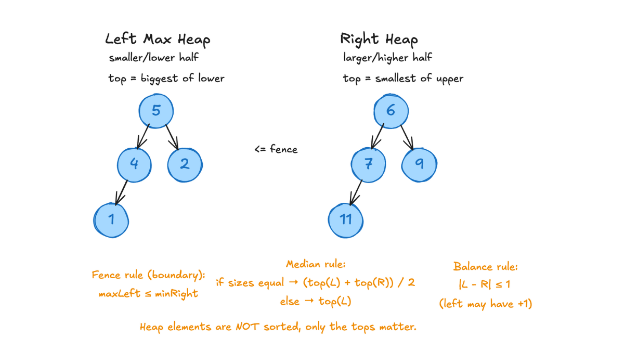>

In [ ]:
import heapq

class MedianFinder:
    def __init__(self):
        self.max_heap = []  # lower half (inverted, so it behaves as max-heap)
        self.min_heap = []  # upper half (regular min-heap)

    def add_num(self, num):
        # Step 1: Always push to max_heap first (lower half)
        heapq.heappush(self.max_heap, -num)  # negate for max-heap behavior

        # Step 2: Balance — ensure every max_heap element <= every min_heap element
        # (move the largest of the lower half into the upper half)
        heapq.heappush(self.min_heap, -heapq.heappop(self.max_heap))

        # Step 3: Rebalance sizes — max_heap should have equal or one more than min_heap
        if len(self.min_heap) > len(self.max_heap):
            heapq.heappush(self.max_heap, -heapq.heappop(self.min_heap))

    def find_median(self):
        if len(self.max_heap) > len(self.min_heap):
            return -self.max_heap[0]  # odd total: lower half has the extra element
        return (-self.max_heap[0] + self.min_heap[0]) / 2  # even total: average both tops


if __name__ == "__main__":
    mf = MedianFinder()
    stream = [5, 15, 1, 3, 8, 7, 9, 10]

    for num in stream:
        mf.add_num(num)
        print(f"Added {num:>3} → Median so far: {mf.find_median()}")

Added   5 → Median so far: 5
Added  15 → Median so far: 10.0
Added   1 → Median so far: 5
Added   3 → Median so far: 4.0
Added   8 → Median so far: 5
Added   7 → Median so far: 6.0
Added   9 → Median so far: 7
Added  10 → Median so far: 7.5


## Pattern 27 — Kth Largest Element

**Importance:** ★★★★★

### Story
This is a focused version of Top-K. Instead of keeping all K items, you only need the Kth largest one.

### When to Use
*   Kth largest in array
*   Streaming ranking queries

### Core Idea
Again use a min-heap of size K. The root always becomes the Kth largest.

### Pitfalls
*   Not popping when heap exceeds size K

### Mini Example
**Example:** `nums=[3,2,1,5,6,4], k=2` → 5.

![][image1]

[image1]: <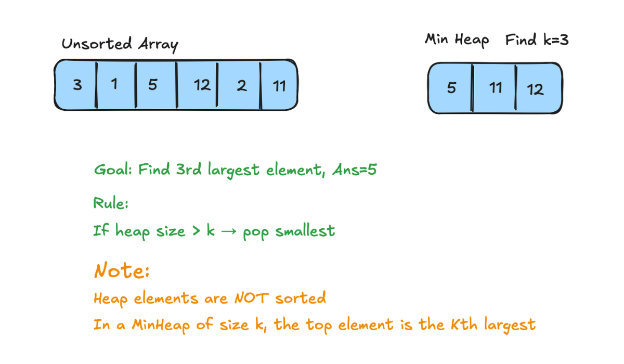>

In [ ]:
import heapq
def kthLargest(nums:list, k:int)->list:
  min_heap = []
  for num in nums:
    heapq.heappush(min_heap, num)
    if len(min_heap)>k:
      heapq.heappop(min_heap)
  return min_heap[0]

kthLargest([3,1,5,12,2,11], k=3)



5

## Pattern 28 — Top-K Frequent Elements

**Importance:** ★★★★★

### Story
First count the frequency of each element. Then maintain a heap of the K most frequent.

### When to Use
*   Most frequent words
*   Trending items
*   Log analysis

### Core Idea
Build a freq map → push into min-heap sorted by frequency → if size > K, pop.

### Pitfalls
*   Incorrect frequency counting
*   Using wrong heap (max-heap)

### Template Code (JavaScript)

In [ ]:
import heapq
from collections import Counter

def get_top_k_frequent_manual(logs, k):
    frequency_map = Counter(logs)

    min_heap = []
    for word, freq in frequency_map.items():
        heapq.heappush(min_heap, (freq, word))
        if len(min_heap) > k:
            heapq.heappop(min_heap)  # remove least frequent

    # Heap has k elements, sorted ascending by freq — reverse for descending
    result = [word for freq, word in sorted(min_heap, reverse=True)]
    return result


if __name__ == "__main__":
    search_logs = [
        "iphone", "laptop", "iphone", "headphones", "laptop",
        "iphone", "shoes", "laptop", "headphones", "iphone",
        "tablet", "shoes", "laptop", "headphones", "headphones"
    ]
    print(get_top_k_frequent_manual(search_logs, 3))

['laptop', 'iphone', 'headphones']


## Pattern 29 — Merge K Sorted Lists

**Importance:** ★★★★★

### Story
You're building a music app that shows one unified "Recently Played" feed, merged from 3 devices — phone, laptop, and tablet. Each device already has its own songs sorted by timestamp. You need to merge all 3 into a single sorted feed, without just dumping everything together and re-sorting from scratch.

```
Phone:   [1, 4, 7]
Laptop:  [2, 5, 8]
Tablet:  [3, 6, 9]

Merged:  [1, 2, 3, 4, 5, 6, 7, 8, 9]
```
**The "aha" trick**

Instead of combining all songs into one giant list and sorting it (slow, wasteful — you'd be re-sorting stuff that's already sorted), you keep a small heap with just the "front" song from each device.

Every time you pick the smallest song off the heap, you immediately peek at that same device and pull its next song into the heap. You're never looking at more than 3 songs at once (one per device) — just constantly swapping out "whoever's turn it is" for "whoever's next."

Think of it like 3 people in 3 different lines, each holding a numbered ticket in order. You always call out the smallest ticket number across all 3 lines, and whoever handed you that ticket immediately shows you their next one.

### When to Use
*   Merging sorted data streams
*   Log merging
*   External sort

### Core Idea
Push each list’s head into a min-heap → pop smallest → push its next.

### Mini Example
**Example:** merging 3 sorted linked lists using a heap.

![][image1]

[image1]: <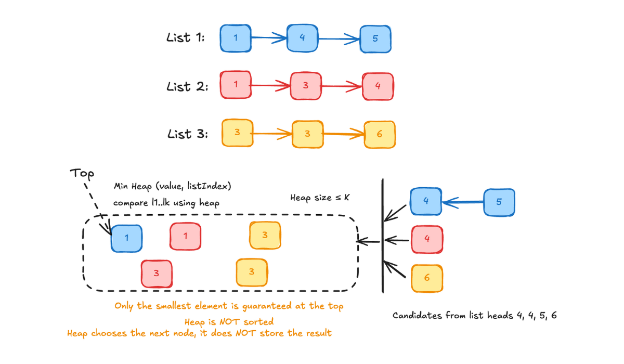>

In [ ]:
import heapq

def merge_k_sorted_lists(lists):
    min_heap = []
    result = []

    # Step 1: push the first song from each device, tagging WHICH device it came from
    for device_index, song_list in enumerate(lists):
        if song_list:  # skip empty devices
            first_song = song_list[0]
            heapq.heappush(min_heap, (first_song, device_index, 0))
            # (song_value, which_device, position_in_that_device's_list)

    # Step 2: keep pulling the smallest song, then refill from the same device
    while min_heap:
        song, device_index, position = heapq.heappop(min_heap)
        result.append(song)

        # if that device has more songs, push its next one
        next_position = position + 1
        if next_position < len(lists[device_index]):
            next_song = lists[device_index][next_position]
            heapq.heappush(min_heap, (next_song, device_index, next_position))

    return result


# --- Simulate 3 devices with sorted "recently played" timestamps ---
phone = [1, 4, 7]
laptop = [2, 5, 8]
tablet = [3, 6, 9]

merged_feed = merge_k_sorted_lists([phone, laptop, tablet])
print("Merged feed:", merged_feed)

[[1, 4, 7], [2, 5, 8], [3, 6, 9]] lists
Merged feed: [1, 2, 3, 4, 5, 6, 7, 8, 9]


## Pattern 30 — Dijkstra’s Algorithm (Weighted Shortest Path)

**Importance:** ★★★★

### Story
You're a delivery driver starting at intersection A in a small town. The roads between intersections take different times to drive (the numbers on each edge). You want to know the fastest time from A to every other intersection in town.

You don't explore roads randomly — you always drive toward whichever unvisited intersection is currently closest to you (by total time so far), lock that time in as final, then check if going through it opens up a shorter path to its neighbors. That's the whole algorithm.

### When to Use
*   Shortest path in weighted graphs
*   Network routing
*   Latency optimization

### Core Idea
*   Use a min-heap of (node, distance). Relax edges and update distances.

### Pitfalls
*   Not skipping outdated distances
*   Using BFS incorrectly on weighted graphs

![][image1]

[image1]: <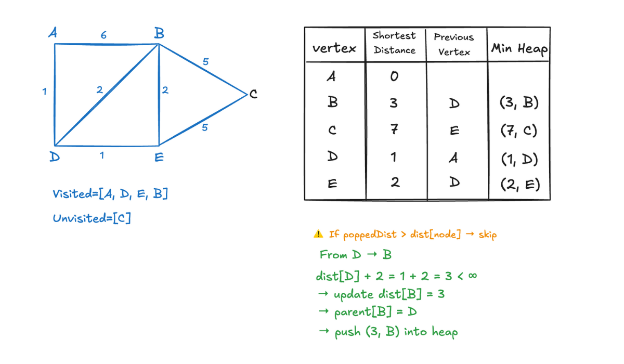>

In [ ]:
import heapq

# Road network: intersection -> {neighbor: drive_time}
roads = {
    'A': {'B': 6, 'D': 1},
    'B': {'A': 6, 'D': 2, 'E': 2, 'C': 5},
    'C': {'B': 5, 'E': 5},
    'D': {'A': 1, 'B': 2, 'E': 1},
    'E': {'D': 1, 'B': 2, 'C': 5}
}

def dijkstra(graph, start):
    # Step 1: every intersection starts "unreachable" except the driver's start point
    dist = {node: float('inf') for node in graph}
    dist[start] = 0
    parent = {node: None for node in graph}
    visited = set()

    # Min-heap: (time_so_far, intersection)
    min_heap = [(0, start)]

    while min_heap:
        current_dist, current_node = heapq.heappop(min_heap)

        # Skip stale entries — we already found a faster way here before
        if current_dist > dist[current_node]:
            continue

        # Lock in this intersection's shortest time — it's now "visited"
        visited.add(current_node)

        # Check every road out of this intersection
        for neighbor, drive_time in graph[current_node].items():
            if neighbor in visited:
                continue

            new_dist = current_dist + drive_time

            # Found a faster way to reach neighbor? Update it.
            if new_dist < dist[neighbor]:
                dist[neighbor] = new_dist
                parent[neighbor] = current_node
                heapq.heappush(min_heap, (new_dist, neighbor))

    return dist, parent


def print_route(parent, start, destination):
    """Reconstructs the actual path the driver takes, not just the total time."""
    path = []
    node = destination
    while node is not None:
        path.append(node)
        node = parent[node]
    path.reverse()
    return " → ".join(path)


# --- Run it ---
distances, parents = dijkstra(roads, 'A')

print("Fastest time from A to every intersection:\n")
for intersection in sorted(distances):
    time = distances[intersection]
    route = print_route(parents, 'A', intersection)
    print(f"  A → {intersection}: {time} min   (route: {route})")

Fastest time from A to every intersection:

  A → A: 0 min   (route: A)
  A → B: 3 min   (route: A → D → B)
  A → C: 7 min   (route: A → D → E → C)
  A → D: 1 min   (route: A → D)
  A → E: 2 min   (route: A → D → E)


## Pattern 31 — 1D Dynamic Programming

**Importance:** ★★★★★

### Story
1D DP solves problems by building solutions for small indexes and reusing them for larger ones. Each state depends on a small number of previous states.

### When to Use
*   Fibonacci
*   Climbing stairs
*   House robber

### Core Idea
State transition: `dp[i] = best value using dp[i-1], dp[i-2], etc.`

### Pitfalls
*   Incorrect base cases
*   Confusing dp indexing

### Mini Example
**Example:** `n=4` → 5 ways to climb.

![][image1]

[image1]: <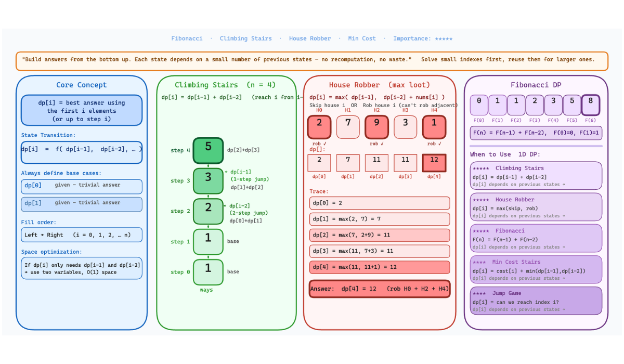>

In [ ]:
def climb_n_stairs(n):
  if n < 0: return 0 # Handle negative input if necessary
  if n <= 2: return n

  # Initialize dp array with size n+1
  # dp[i] will store the number of ways to climb i stairs
  dp = [0] * (n + 1)
  dp[1] = 1 # One way to climb 1 stair
  dp[2] = 2 # Two ways to climb 2 stairs (1+1 or 2)

  for i in range(3, n+1):
    dp[i] = dp[i-1] + dp[i-2]
  return dp[n]

climb_n_stairs(4)

5

## Pattern 32 — 2D Dynamic Programming

**Importance:** ★★★★★

### Story
You're walking from the top-left corner of a city grid to the bottom-right corner. You can only move right or down — never left or up. Every block you step into costs a toll (that's grid[r][c]). You want the cheapest total route.

Here's the key trick that makes this solvable without checking every possible path: to arrive at any intersection, you must have come from either directly above it or directly to its left — there's no other way, since you only move right/down. So the cheapest way to reach any intersection is: (cheapest way to reach the intersection above) OR (cheapest way to reach the intersection to the left), whichever is smaller, plus this intersection's own toll.

### When to Use
*   Min path sum
*   Edit distance
*   Sequence alignment

### Core Idea
Fill `dp[r][c]` after initializing first row and column.

### Pitfalls
*   Incorrect initialization of base row/column

### Mini Example
**Example:** `grid=[[1,3,1],[1,5,1],[4,2,1]]` → min sum = 7.

![][image1]

[image1]: <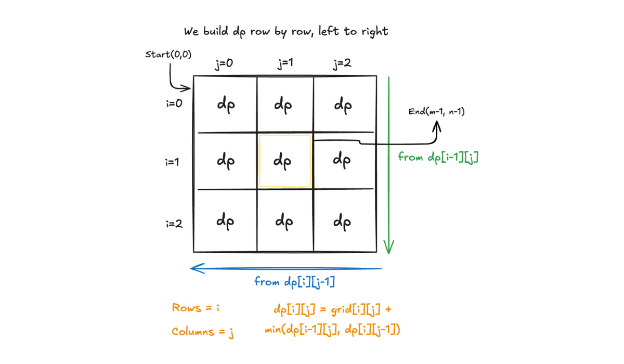>

In [ ]:
def minPathSum(grid):
  R = len(grid)
  C = len(grid[0])
  dp = [[0] * C for _ in range(R)]
  dp[0][0] = grid[0][0]

  for r in range(1, R): dp[r][0] = dp[r-1][0] + grid[r][0]
  for c in range(1, C): dp[0][c] = dp[0][c-1] + grid[0][c]

  for r in range(1, R):
    for c in range(1, C):
      # Corrected from math.min to Python's built-in min()
      dp[r][c] = min(dp[r-1][c], dp[r][c-1]) + grid[r][c]

  return dp[R-1][C-1]

grid=[[1,3,1],[1,5,1],[4,2,1]]
minPathSum(grid)


7

## Pattern 34 — Knapsack DP (0/1)

**Importance:** ★★★★★

### Story
You're a thief with one bag that holds up to a fixed weight. You're standing in a room full of items — each has a weight and a value. For each item, you can only grab it once (no duplicates), and once you decide, you move to the next item. Your goal: leave with the most value possible without the bag ripping.

### Why backward matters
If you scan capacities forward, you might accidentally "reuse" the same item twice in your bag — like grabbing the same painting twice because your bag still shows room from before you took it. Going backward locks in that each item is only counted once.

### Pattern sentence to remember
"For each item, decide take-or-leave, walking capacity from high to low so you never double-dip on the same item."

### When to Use
*   0/1 Knapsack
*   Resource allocation

### Core Idea
Traverse capacities backward: `dp[c] = max(dp[c], value + dp[c-weight])`.

### Pitfalls
*   Traversing forward breaks correctness


![][image1]

[image1]: <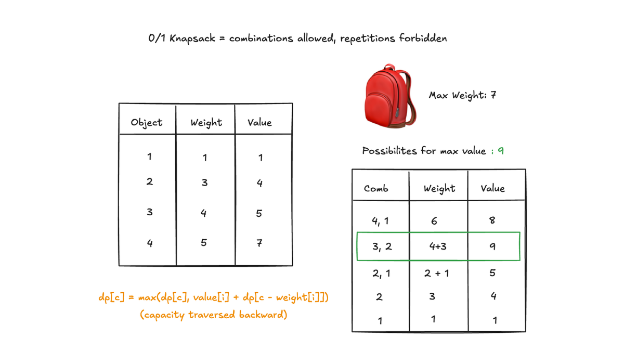>

In [2]:
def knapsack(weights, values, cap):
    dp = [0] * (cap + 1)
    for i in range(len(weights)):
        for c in range(cap, weights[i] - 1, -1):
            dp[c] = max(dp[c], values[i] + dp[c - weights[i]])
    return dp[cap]

weights = [1,3,4,5]
values  = [1,4,5,7]
cap = 7

print(knapsack(weights, values, cap))  # 7

7


## Pattern 35 — Backtracking

**Importance:** ★★★★★

### Story
Backtracking explores possibilities like navigating a decision tree. You choose, explore deeper, then undo and try alternatives.

### When to Use
*   Combinations
*   Permutations
*   Subsets
*   Constraint solving

### Core Idea
Backtracking template: choose → recurse → unchoose.

### Pitfalls
*   Not undoing choice leads to incorrect paths

### Mini Example
**Example:** subsets of `[1,2,3]`.

![][image1]

[image1]: <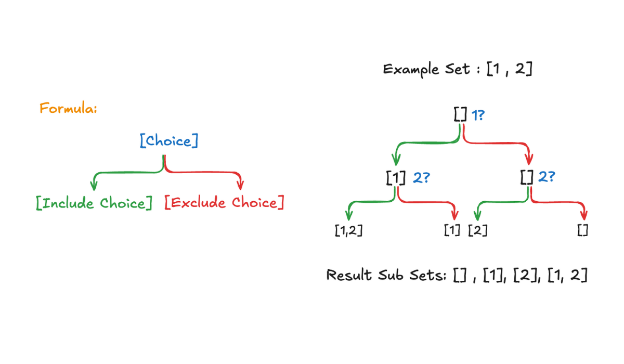>

                 (start)
                /        \
           Door 1        Door 2
             |               |
          [1]              [2]
             |               |
          Door 2          (no doors left)
             |
          [1,2]




START (path = [])
│
├── Right Door 1 (append 1) → path = [1]
│   │
│   └── Right Door 2 (append 2) → path = [1,2]   ← dead end here
│       └── pop 2 → path = [1]
│   │
│   (no more doors in this room)
│   └── pop 1 → path = []
│
├── back at START (path = [])
│
└── Right Door 2 (append 2) → path = [2]   ← dead end here
    └── pop 2 → path = []

(no more doors at START)
DONE

In [9]:
def subsets(nums):
    result = []

    def backtrack(path, start):
        result.append(path[:])  # save current subset immediately
        for i in range(start, len(nums)):
            path.append(nums[i])
            backtrack(path, i + 1)
            path.pop()

    backtrack([], 0)
    return result


print(subsets([1, 2, 3]))

[[], [1], [1, 2], [1, 2, 3], [1, 3], [2], [2, 3], [3]]


In [10]:
def subsets(nums):
    result = []

    def backtrack(index, current):
        # Base case: we've decided on all elements
        if index == len(nums):
            result.append(current[:])  # save a copy
            return

        # Choice 1: include nums[index]
        current.append(nums[index])
        backtrack(index + 1, current)
        current.pop()  # undo the include (backtrack)

        # Choice 2: exclude nums[index]
        backtrack(index + 1, current)

    backtrack(0, [])
    return result


print(subsets([1, 2]))
# [[1, 2], [1], [2], []]

[[1, 2], [1], [2], []]


## Pattern 36 — Trie (Prefix Tree)
**Importance:** ★★★★

### Story
A trie is like a dictionary tree where each path from the root spells a word. It gives lightning-fast prefix searches and is perfect for autocomplete systems.

### When to Use
- Autocomplete
- Prefix matching
- Word dictionary lookups

### Core Idea
Each node stores children and an endOfWord flag. Walk character by character.

### Pitfalls
- Not marking the end of word correctly
- Creating unnecessary nodes

### Mini Example
Example: Insert 'car' and 'cat'; both share prefix 'ca'.

![][image1]

[image1]: <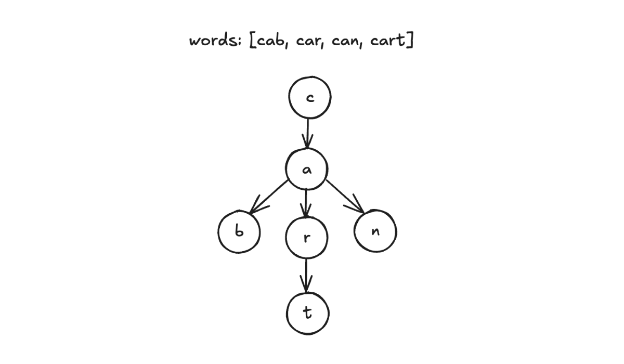>

In [16]:
class Trie:
    def __init__(self):
        self.root = {}

    def insert(self, word: str) -> None:
        node = self.root
        for char in word:
            if char not in node:
                node[char] = {}
            node = node[char]
        node['#'] = True  # Mark end of word

    def search(self, word: str) -> bool:
        node = self.root
        for char in word:
            if char not in node:
                return False
            node = node[char]
        return '#' in node

    def startsWith(self, prefix: str) -> bool:
        node = self.root
        for char in prefix:
            if char not in node:
                return False
            node = node[char]
        return True


trie = Trie()
trie.insert("apple")
trie.insert("apricot")

print(trie.search("apple"))  # True
print(trie.search("app"))    # False

True
False


## Pattern 37 — Bit Manipulation
**Importance:** ★★★★

### Story
Imagine you need to find a single unique element in an array where every other number appears twice—but you only have microseconds to spare. Bit operations let you work at the hardware level, treating numbers as sets of individual switches. XOR is your best friend here: when you XOR two identical numbers, they cancel out to zero. Bitmasks let you generate all possible subsets in compact form, and bit shifts perform lightning-fast multiplication or division by powers of two. It's the secret weapon that separates code that runs in milliseconds from code that runs in seconds.

### When to Use
- Finding unique elements via XOR (single number appears once, rest appear twice)
- Generating or checking subsets with bitmasks
- Performance-critical code requiring low-level optimizations
- Checking/setting individual flags in a compact way

### Core Idea
Leverage XOR for cancelation (identical values vanish), bitmasks to represent subsets compactly, and shifts to multiply/divide by powers of 2 without arithmetic overhead.

### Pitfalls
- Forgetting operator precedence (XOR has lower precedence than comparison operators)
- Confusing left shift `<<` (multiply) vs. right shift `>>` (divide)
- Mixing up bitwise (`&`, `|`) vs. logical (`and`, `or`) operators in Python

### Mini Example
**Example:** Unique number `[4,1,2,1,2]` ---> 4.

![][image1]

[image1]: <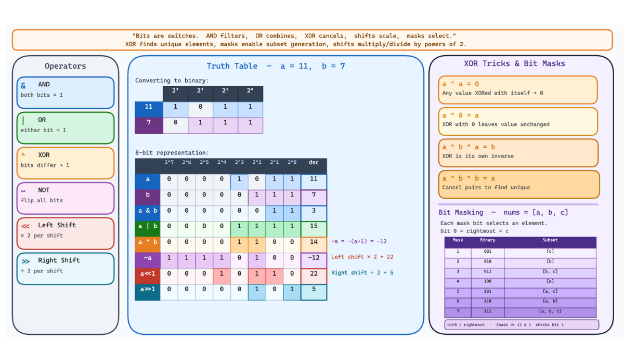>

In [17]:
# ---------- Basic Operators ----------
a = 11   # binary: 1011
b = 7    # binary: 0111

print("a & b  =", a & b)   # AND: both bits 1        → 3   (0011)
print("a | b  =", a | b)   # OR: either bit 1         → 15  (1111)
print("a ^ b  =", a ^ b)   # XOR: bits differ         → 14  (1110)
print("~a     =", ~a)      # NOT: flips all bits      → -12
print("a << 1 =", a << 1)  # Left shift: ×2           → 22
print("a >> 1 =", a >> 1)  # Right shift: ÷2          → 5


# ---------- XOR Tricks ----------
print("\nXOR tricks:")
print("a ^ a =", a ^ a)          # always 0
print("a ^ 0 =", a ^ 0)          # always a
print("a ^ b ^ a =", a ^ b ^ a)  # cancels back to b

# Classic use: find the one unique number in a list where
# every other number appears twice
nums = [4, 1, 2, 1, 2]
unique = 0
for n in nums:
    unique ^= n
print("Unique number:", unique)  # 4


# ---------- Bit Masking for Subsets ----------
def subsets_bitmask(nums):
    n = len(nums)
    result = []

    for mask in range(2 ** n):          # try every number from 0 to 2^n - 1
        subset = []
        for i in range(n):
            if (mask >> i) & 1:          # check if bit i is set
                subset.append(nums[i])
        result.append(subset)

    return result


print("\nSubsets of [a, b, c]:")
for s in subsets_bitmask(['a', 'b', 'c']):
    print(s)

a & b  = 3
a | b  = 15
a ^ b  = 12
~a     = -12
a << 1 = 22
a >> 1 = 5

XOR tricks:
a ^ a = 0
a ^ 0 = 11
a ^ b ^ a = 7
Unique number: 4

Subsets of [a, b, c]:
[]
['a']
['b']
['a', 'b']
['c']
['a', 'c']
['b', 'c']
['a', 'b', 'c']


## Pattern 38 — Intervals
**Importance:** ★★★★★

### Story
Imagine you're managing conference rooms and you have 100 meeting requests for the next month. Some overlap. Some nest inside others. Some touch at the edges. How do you find the minimum number of rooms needed? How do you find which requests conflict? Intervals are like events on a timeline, and the magic trick is simple: sort by start time first, then walk through merging any that overlap. This one pattern solves scheduling problems, collision detection, and range merging that otherwise look impossible.

### When to Use
- Meeting room scheduling (minimum rooms needed)
- Insert interval into a sorted list without creating overlaps
- Merge overlapping intervals into disjoint ranges
- Conflict detection and range union problems

### Core Idea
Sort intervals by start time, then iterate through merging whenever `next.start ≤ current.end`. This collapses all overlaps in one pass.

### Pitfalls
- Forgetting to sort before merging (order matters!)
- Incorrect boundary comparisons (≤ vs. <, which determines if touching intervals merge)
- Not updating the end time correctly when merging

### Mini Example
Example: `[[1,3],[2,6]]` → `[[1,6]]` (overlapping intervals merge into one)

![][image1]

[image1]: <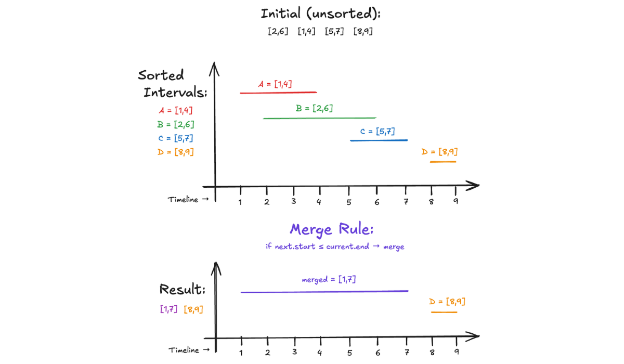>

In [19]:
def merge_intervals(intervals):
    intervals.sort(key=lambda x: x[0])
    res = [intervals[0]]
    for i in range(1, len(intervals)):
        last = res[-1]
        if intervals[i][0] <= last[1]:
            last[1] = max(last[1], intervals[i][1])
        else:
            res.append(intervals[i])
    return res


print(merge_intervals([[1,3],[2,6]]))
# [[1, 6], [8, 10], [15, 18]]

[[1, 6]]


## Pattern 39 — Divide & Conquer
**Importance:** ★★★

### Story
Imagine you need to sort a million bank transactions before midnight. Trying to sort them linearly would take forever. But what if you split them in half, sorted each half separately (which you could even do in parallel), and then merged two sorted lists back together? That's divide and conquer: it turns an impossibly large problem into dozens of tiny, manageable pieces. Merge sort runs in $O(n \log n)$ instead of $O(n^2)$ precisely because it splits the work cleverly.

### When to Use
- Merge sort (guaranteed $O(n \log n)$ sorting)
- Quick sort (average $O(n \log n)$ sorting with small space)
- Binary search and binary search tree problems
- Tree traversals and multi-branch recursion
- Finding closest pair, maximum subarray, etc.

### Core Idea
1. **Divide**: Split the input into smaller subproblems (usually halves)
2. **Conquer**: Solve each subproblem recursively
3. **Combine**: Merge or combine the results back together

### Pitfalls
- Not defining a correct base case (infinite recursion)
- Combining results incorrectly (most common bug)
- Not recognizing when the problem can't be cleanly divided in half
- Excess space/time complexity in the combine step

### Mini Example
Example: Sorting `[3, 1, 4, 1, 5]` via merge sort splits into `[3,1]` and `[4,1,5]`, sorts each, then merges to `[1,1,3,4,5]`.

![][image1]

[image1]: <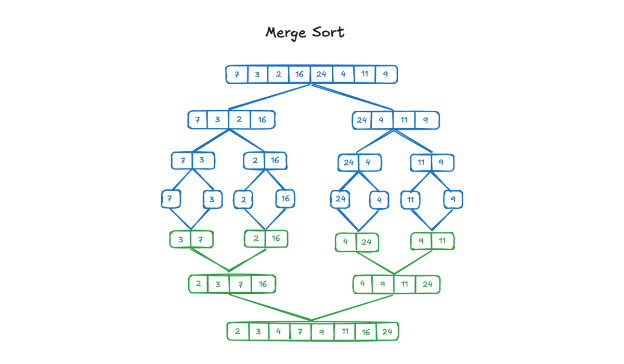>

In [23]:

from collections import deque

def merge(head, tail):
    head, tail = deque(head), deque(tail)
    merged = []

    while head and tail:
        if head[0] <= tail[0]:
            merged.append(head.popleft())
        else:
            merged.append(tail.popleft())

    merged.extend(head)
    merged.extend(tail)
    return merged

def merge_sort(arr):
    if len(arr) <= 1:
        return arr

    mid = len(arr) // 2
    head_arr = merge_sort(arr[:mid])
    tail_arr = merge_sort(arr[mid:])

    return merge(head_arr, tail_arr)

print(merge_sort([3,1,4,1,5]))

[1, 1, 3, 4, 5]


## Pattern 40 — Math Patterns
**Importance:** ★★★

### Story
Imagine you need to find the greatest common divisor of two 100-digit numbers, or check if 1 billion is prime, or find all primes up to 1 million. A naive approach would time out. But 2,000 years ago, Euclid discovered that GCD(a, b) = GCD(b, a mod b) — a simple observation that solves the problem in microseconds instead of milliseconds. Similarly, the Sieve of Eratosthenes finds all primes up to N in $O(N \log \log N)$ instead of checking each number individually. Good math is a superpower.

### When to Use
- Prime number queries and prime factorization
- Finding GCD and LCM efficiently
- Modulo arithmetic for large numbers
- Counting divisors or computing totient function
- Fraction reduction and ratio problems

### Core Idea
- **GCD via Euclid**: $\gcd(a, b) = \gcd(b, a \bmod b)$ until b = 0
- **Sieve of Eratosthenes**: Mark multiples of each prime to find all primes up to N
- **Modular arithmetic**: Use mod to prevent overflow and exploit periodicity

### Pitfalls
- Incorrect base cases (when does recursion/iteration stop?)
- Inefficient prime checking (trial division on every number is slow)
- Off-by-one errors in sieve initialization
- Not handling edge cases (0, 1, negative numbers)

### Examples
**GCD Example**: $\gcd(48, 18) = \gcd(18, 12) = \gcd(12, 6) = \gcd(6, 0) = 6$

**Sieve Example**: Find all primes ≤ 10: [2, 3, 5, 7] (mark off 4, 6, 8, 9, 10 as composites)

![][image1]

[image1]: <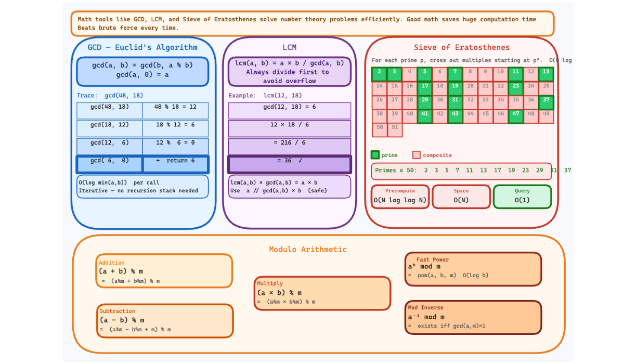>

In [ ]:
# GCD (Euclid) — the sentence: "The GCD of two numbers also divides their remainder, so you can keep shrinking the problem until one side hits 0."
def gcd(a, b):
    while b:
        a, b = b, a % b
    return a

print(gcd(48, 18))  # 6
# Trace: (48,18) → (18,12) → (12,6) → (6,0) → return 6. Matches your example exactly.


# LCM — the sentence: "LCM and GCD are linked by a * b = gcd(a,b) * lcm(a,b), so once you have GCD, LCM is just division."
def lcm(a, b):
    return a * b // gcd(a, b)

print(lcm(4, 6))  # 12
# Why // and not /: a * b is always divisible by gcd(a,b) exactly, so integer division is safe and avoids float errors on big numbers.

# Sieve of Eratosthenes — the sentence: "Every composite number has a smallest prime factor, so if you cross out all multiples of each prime as you find it, whatever survives is prime."
def sieve(n):
    is_prime = [True] * (n + 1)
    is_prime[0] = is_prime[1] = False

    for i in range(2, int(n**0.5) + 1):
        if is_prime[i]:
            for multiple in range(i*i, n + 1, i):
                is_prime[multiple] = False

    return [i for i, prime in enumerate(is_prime) if prime]

print(sieve(10))  # [2, 3, 5, 7]





6
12
[2, 3, 5, 7]


## Pattern 41 — Sweep Line Algorithm
**Importance:** ★★★★

### Story
Your company books 1,000 meeting rooms across 50 locations over a month. At 2:47 PM on Tuesday, 247 meetings are happening simultaneously—but you need to know: what's the **peak occupancy**? How many physical rooms do you actually need to buy? Checking every second is impossibly slow ($O(n \cdot m)$). But here's the insight: convert each meeting into two events—a "start" and an "end"—sort them, and sweep through time while counting active intervals. Suddenly, a problem that looked intractable becomes $O(n \log n)$.

### When to Use
- Finding maximum overlapping intervals (conference rooms, concurrent tasks, network connections)
- Skyline problem (building silhouettes, calendar busy blocks, video frames)
- Meeting room allocation and booking systems
- Task scheduling and resource utilization
- Event interval processing and collision detection
- Coordinate compression for geometric problems

### Core Idea
1. Convert each interval `[start, end]` into two events: `(start, +1)` and `(end, -1)`
2. Sort events by time; carefully handle ties (typically process **ends before starts** to avoid double-counting)
3. Sweep through sorted events, maintaining a running count of active intervals
4. Track the maximum count, or record the state at each critical point

### Pitfalls
- **Event tie-breaking**: When a meeting ends at 3:00 PM and another starts at 3:00 PM, do they overlap? The answer depends on your problem—be consistent with `<` vs `≤`
- Forgetting to sort the event list (sweep only works on sorted data)
- Mishandling the order of +1 vs -1 at identical timestamps
- Off-by-one errors in boundary conditions
- Not resetting or properly tracking state between critical events

### Example
**Meetings**: `[(1,3), (2,5), (3,6), (4,8)]`

**Events** (sorted): `[(1,+1), (2,+1), (3,-1), (3,+1), (5,-1), (6,-1), (8,-1)]`

**Sweep result**: 
- Time 1: count=1
- Time 2: count=2
- Time 3: count=2 (end then start)
- Time 5: count=1
- Time 8: count=0

**Answer**: Maximum overlapping = **2 rooms needed**

![][image1]

[image1]: <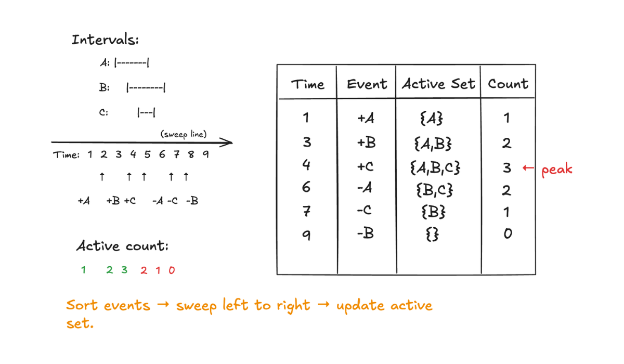>

In [ ]:
def max_overlap(intervals):
    events = []
    for s, e in intervals:
        events.append((s, 1))    # interval starts → +1
        events.append((e, -1))   # interval ends   → -1

    # sort by time; if tie, process 'end' (-1) before 'start' (+1)
    events.sort(key=lambda x: (x[0], x[1]))

    active = max_active = 0
    for _, v in events:
        active += v
        max_active = max(max_active, active)

    return max_active

max_overlap([[1,3],[2,5],[3,6],[4,8]])  # 3

3

## Pattern 42 — Geometry Patterns
**Importance:** ★★★

### Story
You're building a GPS system that needs to find the closest two delivery trucks among 1 million vehicles scattered across a city. Or a self-driving car that must compute which obstacle is about to collide with it. Geometry algorithms solve this in $O(n \log n)$ instead of $O(n^2)$ brute force. These patterns leverage **orientation**, **cross products**, and **coordinate systems** to solve spatial problems elegantly—the hidden math behind graphics, robotics, and navigation.

### When to Use
- Convex hull and boundary computation
- Closest pair of points (nearest neighbor search)
- Line segment intersection detection
- Point-in-polygon tests
- Angle and orientation computation
- Polygon area and centroid calculation
- Coordinate geometry and sweep line with geometry

### Core Idea
- **Cross product** (orientation): Determine if point C is left/right of line AB → $\text{sign}((B_x - A_x)(C_y - A_y) - (B_y - A_y)(C_x - A_x))$
- **Distance formula**: $d = \sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2}$ or squared distance for efficiency
- **Convex hull**: Sort by angle, use monotone stack to eliminate non-convex points
- **Sweep line + geometry**: Combine event sorting with coordinate transformations for collision detection

### Pitfalls
- Floating-point precision errors accumulating through geometric calculations (use integer arithmetic when possible)
- Incorrectly handling **collinear points** (three points on a line)
- Off-by-one in angle sorting or stack management in convex hull
- Confusing cross product sign convention (clockwise vs counterclockwise)
- Edge cases: degenerate inputs (all points same, duplicate points, vertical/horizontal lines)

### Example
**Closest pair of points**: Points = [(0,0), (1,1), (10,10), (11,11)]

**Graham scan convex hull**: Start from lowest point, sort by polar angle, keep only left turns → Result: [(0,0), (11,11), (10,10)] (3 corners)

![][image1]

[image1]: <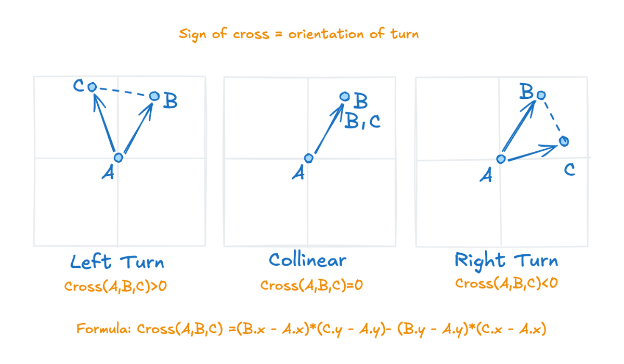>

In [31]:
import math

# ============================================================================
# PATTERN 42 — GEOMETRY PATTERNS: Four Essential Building Blocks
# ============================================================================

# ─────────────────────────────────────────────────────────────────────────
# 1. ORIENTATION: Cross Product (Which way would you turn?)
# ─────────────────────────────────────────────────────────────────────────
# The cross product tells you which way you'd have to turn to walk from A→B→C
# Return 1 (left turn), -1 (right turn), or 0 (collinear/straight through)

def orientation(A, B, C):
    """
    Compute the orientation of the ordered triplet (A, B, C).
    
    Returns:
        1  → Counterclockwise (left turn)
        -1 → Clockwise (right turn)
        0  → Collinear (all three points on same line)
    """
    val = (B[0] - A[0]) * (C[1] - A[1]) - (B[1] - A[1]) * (C[0] - A[0])
    if val == 0:
        return 0  # Collinear
    return 1 if val > 0 else -1  # 1 = CCW, -1 = CW


# Test orientation
print("=" * 60)
print("1. ORIENTATION (Cross Product)")
print("=" * 60)
print(f"orientation((0,0), (1,0), (1,1)) = {orientation((0, 0), (1, 0), (1, 1))}")
print("  → 1 = left turn (counterclockwise)")
print(f"orientation((0,0), (1,0), (1,-1)) = {orientation((0, 0), (1, 0), (1, -1))}")
print("  → -1 = right turn (clockwise)")
print(f"orientation((0,0), (1,0), (2,0)) = {orientation((0, 0), (1, 0), (2, 0))}")
print("  → 0 = collinear (on same line)\n")


# ─────────────────────────────────────────────────────────────────────────
# 2. DISTANCE: Euclidean Distance Between Two Points
# ─────────────────────────────────────────────────────────────────────────
# Standard Pythagorean formula. Tip: when comparing distances, skip sqrt()
# and just compare squared distances—it's faster and avoids float precision.

def dist(p1, p2):
    """
    Compute Euclidean distance between two points p1 and p2.
    """
    return math.sqrt((p1[0] - p2[0])**2 + (p1[1] - p2[1])**2)


def dist_squared(p1, p2):
    """
    Compute squared distance (faster for comparisons, avoids float imprecision).
    Use this when you only need to compare distances, not the actual value.
    """
    return (p1[0] - p2[0])**2 + (p1[1] - p2[1])**2


print("=" * 60)
print("2. DISTANCE")
print("=" * 60)
print(f"dist((0,0), (3,4)) = {dist((0, 0), (3, 4))}")
print("  → Classic 3-4-5 right triangle")
print(f"dist_squared((0,0), (3,4)) = {dist_squared((0, 0), (3, 4))}")
print("  → Avoid sqrt() for comparisons!\n")


# ─────────────────────────────────────────────────────────────────────────
# 3. CLOSEST PAIR: Brute Force O(n²) Algorithm
# ─────────────────────────────────────────────────────────────────────────
# Check every pair of points, keep the pair with the smallest gap.
# Like a lifeguard scanning every pair of swimmers for the two closest.
# Simple, correct, and fine up to ~1,000 points.

def closest_pair(points):
    """
    Find the pair of points with minimum distance (brute force).
    
    Time: O(n²) — fine for small inputs (~1,000 points)
    For millions of points, use divide-and-conquer: O(n log n)
    
    Returns:
        (pair_tuple, min_distance)
    """
    n = len(points)
    best_dist = float('inf')
    best_pair = None
    
    for i in range(n):
        for j in range(i + 1, n):
            d = dist(points[i], points[j])
            if d < best_dist:
                best_dist = d
                best_pair = (points[i], points[j])
    
    return best_pair, best_dist


print("=" * 60)
print("3. CLOSEST PAIR")
print("=" * 60)
points = [(0, 0), (1, 1), (10, 10), (11, 11)]
pair, min_dist = closest_pair(points)
print(f"Points: {points}")
print(f"Closest pair: {pair}")
print(f"Distance: {min_dist:.4f}\n")


# ─────────────────────────────────────────────────────────────────────────
# 4. CONVEX HULL: Monotone Chain Algorithm (Andrew's Algorithm)
# ─────────────────────────────────────────────────────────────────────────
# Sort points left to right, then build the bottom edge and top edge,
# throwing away any point that would create a right turn (non-convex bend).
# More robust than Graham scan (avoids polar angle precision headaches).

def convex_hull(points):
    """
    Compute the convex hull of a set of 2D points.
    Uses the Monotone Chain algorithm (Andrew's algorithm).
    
    Algorithm:
    1. Sort points by x-coordinate (left to right)
    2. Build lower hull: left to right, keeping only left turns
    3. Build upper hull: right to left, keeping only left turns
    4. Concatenate and return
    
    Time: O(n log n) due to sorting
    Space: O(n) for output hull
    
    Returns:
        List of points forming the convex hull (counterclockwise order)
    """
    # Remove duplicates and sort by x, then by y
    points = sorted(set(points))
    
    if len(points) <= 2:
        return points
    
    def build_half_hull(seq):
        """
        Build one half of the convex hull (lower or upper).
        Keep only strict left turns (orientation > 0).
        """
        hull = []
        for p in seq:
            # Pop the last point while it doesn't form a strict left turn
            while len(hull) >= 2 and orientation(hull[-2], hull[-1], p) <= 0:
                hull.pop()
            hull.append(p)
        return hull
    
    # Build lower and upper hulls
    lower = build_half_hull(points)
    upper = build_half_hull(reversed(points))
    
    # Concatenate (skip duplicate endpoints)
    return lower[:-1] + upper[:-1]


print("=" * 60)
print("4. CONVEX HULL")
print("=" * 60)

# Example 1: Square with extra collinear point
print("Example 1: Square with a point on the edge")
pts1 = [(0, 0), (2, 0), (2, 2), (0, 2), (1, 0)]
hull1 = convex_hull(pts1)
print(f"Points: {pts1}")
print(f"Convex hull: {hull1}")
print("  → (1,0) correctly excluded (collinear with (0,0) and (2,0))\n")

# Example 2: Collinear points (degenerate case)
print("Example 2: All collinear points (y = x line)")
pts2 = [(0, 0), (1, 1), (10, 10), (11, 11)]
hull2 = convex_hull(pts2)
print(f"Points: {pts2}")
print(f"Convex hull: {hull2}")
print("  → Degenerates to just the two extremes (only a line segment)\n")

# Example 3: Triangle (generic case)
print("Example 3: Triangle")
pts3 = [(0, 0), (4, 0), (2, 3)]
hull3 = convex_hull(pts3)
print(f"Points: {pts3}")
print(f"Convex hull: {hull3}")
print("  → All three points form the hull (every point is a corner)\n")

1. ORIENTATION (Cross Product)
orientation((0,0), (1,0), (1,1)) = 1
  → 1 = left turn (counterclockwise)
orientation((0,0), (1,0), (1,-1)) = -1
  → -1 = right turn (clockwise)
orientation((0,0), (1,0), (2,0)) = 0
  → 0 = collinear (on same line)

2. DISTANCE
dist((0,0), (3,4)) = 5.0
  → Classic 3-4-5 right triangle
dist_squared((0,0), (3,4)) = 25
  → Avoid sqrt() for comparisons!

3. CLOSEST PAIR
Points: [(0, 0), (1, 1), (10, 10), (11, 11)]
Closest pair: ((0, 0), (1, 1))
Distance: 1.4142

4. CONVEX HULL
Example 1: Square with a point on the edge
Points: [(0, 0), (2, 0), (2, 2), (0, 2), (1, 0)]
Convex hull: [(0, 0), (2, 0), (2, 2), (0, 2)]
  → (1,0) correctly excluded (collinear with (0,0) and (2,0))

Example 2: All collinear points (y = x line)
Points: [(0, 0), (1, 1), (10, 10), (11, 11)]
Convex hull: [(0, 0), (11, 11)]
  → Degenerates to just the two extremes (only a line segment)

Example 3: Triangle
Points: [(0, 0), (4, 0), (2, 3)]
Convex hull: [(0, 0), (4, 0), (2, 3)]
  → All three